In [22]:
## ------- edit params first here --------------

INPUTROOT = 'export_c3/'
OUTPUTROOT = 'report_c3/'

# ------------------------------------------------

# utils for os.path
from os.path import join as J
from os.path import exists as E
from os import listdir as L
import pandas as pd
import numpy as np
pd.set_option('display.max_rows',6)
print('global L,E,J is defined')

#---------------- setup PATHs -------------------
import os
WORKDIR = os.getcwd()

## setup OUTPUTPATH and WOKER
import sys

#---------------- load librarys -------------------

from tqdm.notebook import tqdm

COL_ANNO={"C1":'#F04923',"C2":'#3BA9DD','C3':'#8A9197'}


from sklearn.metrics import roc_curve, auc, RocCurveDisplay, roc_auc_score


import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import label_binarize, StandardScaler
from sklearn.model_selection import KFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.multiclass import OneVsRestClassifier
from sklearn.metrics import roc_curve, auc

import openpyxl

global L,E,J is defined


In [23]:
from sklearn.metrics import roc_curve, auc, RocCurveDisplay, roc_auc_score
from itertools import cycle
import matplotlib.pyplot as plt
from sklearn.preprocessing import label_binarize
# import numpy as np
from sklearn.metrics import confusion_matrix

def plot_auc_3plus(dtc, X, ytruth,
                   class_names =['C1','C2','C3'],
                   colors = cycle(['#F04923', '#3BA9DD','#7CC242']),
                   plot_micro_average_curve = True,
                   fig_title=None
                  ):
    
    # If your target labels are not already binarized (one-hot encoded), you'll need to do so:
    ytruth_bin = label_binarize(ytruth, classes=class_names)
    n_classes = ytruth_bin.shape[1]

    # Predict probabilities
    y_score = dtc.predict_proba(X)

    # Compute ROC curve and ROC area for each class
    fpr = dict()
    tpr = dict()
    roc_auc = dict()

    for i in range(n_classes):
        fpr[i], tpr[i], _ = roc_curve(ytruth_bin[:, i], y_score[:, i])
        roc_auc[i] = auc(fpr[i], tpr[i])
        
    # Compute micro-average ROC curve and ROC area
    if plot_micro_average_curve:
        ytruth_bin_c1_c2 = ytruth_bin[:,:2]
        y_score_c1_c2 = y_score[:,:2]
        fpr["micro"], tpr["micro"], _ = roc_curve(ytruth_bin_c1_c2.ravel(), y_score_c1_c2.ravel())
        roc_auc["micro"] = auc(fpr["micro"], tpr["micro"])
    #return fpr, tpr, roc_auc
    # Plot all ROC curves
    fig = plt.figure(figsize=(8,8))

    for i, color in zip(range(n_classes), colors):
        plt.plot(fpr[i], tpr[i], color=color, lw=2,
                 label='ROC curve of class {0} (area = {1:0.4f})'
                 ''.format(class_names[i], roc_auc[i]))
    if plot_micro_average_curve:
        plt.plot(fpr["micro"], tpr["micro"],
                 label='micro-average ROC curve (C1 & C2) (area = {0:0.4f})'
                       ''.format(roc_auc["micro"]),
                 color='gray', linestyle='--', linewidth=2)

    plt.plot([0, 1], [0, 1], 'k--', lw=2) 
    plt.xlim([-0.01, 1.0]) 
    plt.ylim([0.0, 1.01])
    plt.xlabel('False Positive Rate') 
    plt.ylabel('True Positive Rate') 
    if fig_title is None:
        plt.title('Receiver Operating Characteristic for Multi-Class') 
    else:
        plt.title(fig_title) 
    plt.legend(loc="lower right") 
#     plt.show()

    roc_data = {class_names[i]: pd.DataFrame({'fpr': fpr[i], 'tpr': tpr[i]}) for i in range(n_classes)}
    if plot_micro_average_curve:
        roc_data['micro'] = pd.DataFrame({'fpr': fpr['micro'], 'tpr': tpr['micro']})
    fig.roc_data = roc_data
    return fig 


from typing import Literal
pd.set_option('display.max_rows',6)
print('global L,E,J is defined')

#---------------- setup PATHs -------------------
import os
WORKDIR = os.getcwd()

## setup OUTPUTPATH and WOKER
import sys

#---------------- load librarys -------------------

def write_excel(d,fname,outputdir='report',force_ext:None|Literal['xls','xlsx']=None,max_row=50_000,index=True):
    """
    :engine: 'xlsxwriter' for .xlsx, 'xlwt' for .xls
    ext will be auto determined by the fname when force_ext is None
        if not provide in fname, default is .xlsx
    :max_row: max row number for each sheet, if exceed, skip
    """
    _ = fname.split('.')
    if len(_) > 1:
        ext = _[-1]
        name = ".".join(_[:-1])
    else:
        name = fname
        ext = 'xlsx'
    if force_ext is not None:
        assert type(force_ext) == str, "force_ext must be in ['xls','xlsx']"
        ext = force_ext
    if ext == 'xlsx':
        engine = 'xlsxwriter'
    elif ext == 'xls':
        engine = 'xlwt'
    else:
        ext = 'xlsx'
        engine = 'xlsxwriter'
        # raise Exception(f'auto deteminded ext = {ext}, this is not supported, mainly due to there is dot (.) in your current fname,  please manually set ext to .xlsx or .xls')
    out = J(outputdir, name + '.' + ext)

    with pd.ExcelWriter(out, engine=engine) as writer:
        EXCEL_SHEETS_LIMIT = 255
        count = 0
        sheet_names_used = {}
        l = len(d.keys())
        if  l < EXCEL_SHEETS_LIMIT:
            temp = f'{{:0{len(str(l))}d}}'
        else:
            raise  ValueError(f'too many DataFrames({l}) to be written, maximal 255!')
        for name,df in d.items():
            tp = type(df)
            if tp != pd.DataFrame:
                try:
                    df = pd.DataFrame(df)
                    print(f'covert {name}: {tp} -> {type(df)}')
                except Exception as e:
                    print(f'skip {name}, illegal type {type(df)}')
                    continue
            l = len(df) 
            if l <= max_row:
                count  = count + 1
                cc = temp.format(count)
                print(f'  append #{cc} Sheet [{name}]')
                if len(name) > 30:
                    name = name[:28]
                if name in sheet_names_used.keys():
                    suffix = sheet_names_used[name]
                    if suffix > 100:
                        print(f'[ERR] too many(>100) sheets with the same name! skip sheet {name} : {suffix}')
                    name = name + str(suffix)
                    sheet_names_used[name] += 1
                else:
                    sheet_names_used[name] = 0
                # change any df column with dtype of datetime64+time zone to str, as current xlwt does not support datetime with time zone info format
                mask = pd.Series([pd.api.types.is_datetime64_any_dtype(i) for i in df.dtypes])
                df = df.astype({i:str for i in df.columns[mask]})
                df.to_excel(writer,sheet_name=name,index=index)
            else:
                print(f'⛔ skip [{name}.dfx] for it contains {l} rows exceeding max_row setting.')
#     writer.save()
    print(f'writing 1 .xls @ {out}')

    

global L,E,J is defined


# fig 4 S6

## Prepare Data

### wash IHC input mat

In [3]:
rawdata_ihc_v52 = 'external_data/IHC/02师姐返回52例分子分型前瞻验证4marker染色评分v3.0（三分型后重评，删除vim增加GSDME）.xlsx'
rawdata_ihc_t77 = "external_data/IHC/77例non-pCR回顾性队列分子分型marker-IHC染色评分v3.1（三分型版本250329）.xlsx"


In [4]:
book52 = openpyxl.load_workbook(rawdata_ihc_v52)
book77 = openpyxl.load_workbook(rawdata_ihc_t77)

book77.sheetnames

['CANT1', 'MRE11', 'GSDME', 'CD8', '仅使用IHC染色评估77例患者的分型']

In [5]:
book52.sheetnames

['CANT1', 'MRE11', 'CD8', 'GSDME', '根据IHC染色进行分子分型与真实分型比较']

In [6]:
def rank(x:[np.array,pd.Series,list]):
    if type(x)==list:
        x = np.array(x)
    mask = ~x.isna()
    y = np.full_like(x,np.nan)
    for t,n in zip([0.05,0.25,0.5,0.75,1],[0,1,2,3,4]):
        to_fill = x <= t
        y[to_fill & mask] = n
        mask = ~to_fill & mask
    if type(x) == pd.Series:
        return pd.Series(y,index=x.index,name=x.name)
    else:
        return y
def rank_cd8(x):
    if type(x)==list:
        x = np.array(x)
    mask = ~x.isna()
    y = np.full_like(x,np.nan)
    for t,n in zip([0.05,0.10,0.20,1],[0,2,4,8]):
        to_fill = x < t
        y[to_fill & mask] = n
        mask = ~to_fill & mask
    if type(x) == pd.Series:
        return pd.Series(y,index=x.index,name=x.name)
    else:
        return y

In [7]:

glx = pd.read_csv('export_by2_86_pCR_nonpCR/wes_glx.dfx',sep='\t')
# glx = glx[glx['Response']!='pCR']
colData = glx[['uid','Custom_Label','Protein_Cluster']].rename(columns={'Custom_Label':'tsb'})
colData['uid'] = colData['uid'].astype(str)
colData['G3'] = ['C1' if i =='C1' else 'C2' if i=='C2' else 'C3' for i in colData['Protein_Cluster']]
mp = colData.set_index('uid')['tsb'].to_dict()
colData

,uid,tsb,Protein_Cluster,G3
0,1428424,P01,C4,Co
1,1448200,P02,C2,C2
2,1418501,P03,C3,Co
...,...,...,...,...
83,1454489,P84,C2,C2
84,1477341,P85,C2,C2
85,1481407,P86,C2,C2


In [8]:
# handle train test
import re
collect = []

for sheetname in ['MRE11', 'CANT1', 'CD8', 'GSDME']:
    df = pd.read_excel(rawdata_ihc_t77,sheet_name=sheetname,engine='openpyxl')
    marker = re.sub('[^A-Z0-9]','',sheetname)
    if marker !='CD8':
        df['Cluster颜色'] = df['Cluster颜色'].astype(int).astype(str)
        df['sit'] = df['染色情况（阴性：0分；+：1分；++：2分；+++：3分）'].fillna(0)
        df['per'] = df['染色比例（0-5%：0分；6-25%：1分；26-50%：2分；51-75%：3分；76-100%：4分）']
        df['IRS'] = df['H-score']
        if df['per'].dtype==int and df['per'].max() <5:
            pass
        else:
            if df['per'].mean() > 5:
                df['per'] = df['per'] / 100
            df['per'] = rank(df['per'])
        #     df['H'] = df['sit'] * df['per']
        mk = df.set_index('Cluster颜色')[['sit','per','IRS']].copy()
        mk.columns = marker+"_"+pd.Series(['sit','per','IRS'])
        mk.index = [mp[i] for i in mk.index]
        mk.index.name = None
        mk.name = marker
        mk = mk.sort_index()
        collect.append(mk)
    else:
        df['Cluster颜色'] = df['Cluster颜色'].astype(int).astype(str)
#         df['CD8'] = pd.Series(df['CD8阳性细胞占肿瘤灶比例（%）'] >= 0.1).astype(int)
        df['CD8_per'] = df['CD8阳性细胞占肿瘤灶比例'] 
        cd8 = df.set_index('Cluster颜色')[['CD8_per']] 
        cd8.index = [mp[i] for i in cd8.index]
        cd8.index.name = None
        # cd8.name = "CD8"
        cd8 = cd8.sort_index()
        cd8['CD8_H'] = rank_cd8(cd8['CD8_per'])
        collect.append(cd8)

matt = pd.concat(collect,axis=1)
matt = matt.astype(float)

matt

,MRE11_sit,MRE11_per,MRE11_IRS,CANT1_sit,CANT1_per,CANT1_IRS,CD8_per,CD8_H,GSDME_sit,GSDME_per,GSDME_IRS
P01,0.0,0.0,0.0,0.0,0.0,0.0,0.05,2.0,1.0,1.0,1.0
P02,0.0,0.0,0.0,1.0,2.0,2.0,0.10,4.0,1.0,1.0,1.0
P03,0.0,0.0,0.0,0.0,0.0,0.0,0.10,4.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...
P84,2.0,2.0,4.0,2.0,3.0,6.0,0.05,2.0,1.0,1.0,1.0
P85,1.0,2.0,2.0,0.0,0.0,0.0,0.10,4.0,2.0,4.0,8.0
P86,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.0,2.0,2.0,4.0


In [9]:
gv = pd.read_csv('external_data/Proteomics52/washed/prt_glx.dfx',sep='\t')
gv = gv[gv['Group']!='pCR']
gv['uid'] = gv['uid'].astype(str)

organ_info = pd.read_excel('external_data/Organoids/湘雅医院前列腺癌类器官队列信息v3.0.xlsx')
organ_info = organ_info[~organ_info['根治术病理号'].isna()][['根治术病理号','类器官序列号']].rename(columns={'根治术病理号':'uid','类器官序列号':'ooid'})
organ_info['uid'] = organ_info['uid'].astype(int).astype(str)
organ_info['oid'] = organ_info['ooid'].str.lstrip('ORG')
sel_organ_uid = ["1528731","1535920","1538224","1554631","1555314","1557024","1563492","1567143","1567947"]
gv = pd.merge(gv, organ_info,on='uid',how='left',suffixes=['','__xx'])
gv['sel'] = ""
mask = gv['uid'].isin(sel_organ_uid)
gv.loc[mask,'sel'] = gv.loc[mask,'oid']
# gv.index = gv['Custom_Label']
gv.sample(8)

,Custom_Label,uid,source,Group,ooid,oid,sel
27,P115,1516992,valid52,non.pCR,NaN,NaN,
42,P131,1552417,valid52,non.pCR,ORG-30,-30,
29,P117,1518995,valid52,non.pCR,NaN,NaN,
...,...,...,...,...,...,...,...
15,P102,1509451,valid52,non.pCR,NaN,NaN,
48,P138,1567947,valid52,non.pCR,ORG-49,-49,-49
10,P097,1499496,valid52,non.pCR,NaN,NaN,


In [10]:
mm = gv[(gv['sel']!='') & ~gv['oid'].isna()].set_index('Custom_Label')['oid'].to_dict()
mm

{'P087': '-36',
 'P088': '-13',
 'P089': '-39',
 'P090': '-37',
 'P091': '-08',
 'P092': '-02',
 'P135': '-43',
 'P137': '-48',
 'P138': '-49'}

In [11]:
# handle valid
collect = []
for sheetname in ['CANT1', 'MRE11', 'GSDME', 'CD8']:
    df = pd.read_excel(rawdata_ihc_v52,sheet_name=sheetname,engine='openpyxl')
    marker = re.sub('[^A-Z0-9]','',sheetname)
    if marker != 'CD8':
    #     df['Cluster颜色'] = df['Cluster颜色'].astype(int).astype(str)
    #     mk = df.set_index('Cluster颜色')['染色比例（0-5%：0分；6-25%：1分；26-50%：2分；51-75%：3分；76-100%：4分）'].fillna(0) / 100
    #     mk.index.name = None
    #     mk.name = marker
    #     mk = mk.sort_index()
    #     mk = rank(mk)
    #     collect.append(mk)
        df['Cluster颜色'] = df['Cluster颜色'].astype(int).astype(str)
        df['sit'] = df['染色情况（阴性：0分；+：1分；++：2分；+++：3分）'].fillna(0)
        df['per'] = df['染色比例（0-5%：0分；6-25%：1分；26-50%：2分；51-75%：3分；76-100%：4分）'].fillna(0)
        df['IRS'] = df['H-score']
        if df['per'].dtype==int and df['per'].max() <5:
            pass
        else:
            if df['per'].mean() > 5:
                df['per'] = df['per'] / 100
            df['per'] = rank(df['per'])
    #     df['H'] = df['sit'] * df['per']
        mk = df.set_index('Cluster颜色')[['sit','per','IRS']].copy()
        mk.columns = marker+"_"+pd.Series(['sit','per','IRS'])
        mk.index.name = None
        mk.name = marker
        mk = mk.sort_index()
        collect.append(mk)

    else:
#         df['CD8'] = pd.Series(df['染色比例（0-5%：0分；6-25%：1分；26-50%：2分；51-75%：3分；76-100%：4分）'] >= 0.1).astype(int)
        df['CD8_per'] = df['染色比例（%）']
        df['Cluster颜色'] = df['Cluster颜色'].astype(int).astype(str)
        cd8 = df.set_index('Cluster颜色')[['CD8_per']]
        cd8.index.name = None
        # cd8.name = "CD8"
        cd8 = cd8.sort_index()
        if cd8['CD8_per'].mean() > 1:
            cd8['CD8_per'] = cd8['CD8_per'] / 100
        cd8['CD8_H'] = rank_cd8(cd8['CD8_per'])
        collect.append(cd8)

matv = pd.concat(collect, axis=1)
matv = matv.loc[gv['uid']]
matv.index = gv['Custom_Label']
matv.index.name =None
matv = matv[matt.columns]
matv


,MRE11_sit,MRE11_per,MRE11_IRS,CANT1_sit,CANT1_per,CANT1_IRS,CD8_per,CD8_H,GSDME_sit,GSDME_per,GSDME_IRS
P087,0,0,0,0,0,0,0.0,0.0,2,1,2
P088,1,4,4,1,2,2,0.2,8.0,0,0,0
P089,2,4,8,1,4,4,0.0,0.0,2,2,4
...,...,...,...,...,...,...,...,...,...,...,...
P135,0,0,0,0,0,0,0.0,0.0,1,1,1
P137,1,1,1,1,1,1,0.1,4.0,0,0,0
P138,0,0,0,0,0,0,0.3,8.0,0,0,0


In [12]:
matt.to_csv('export_c3/fig4_ihc_mat_retrospective.dfx',sep='\t')
matv.to_csv('export_c3/fig4_ihc_mat_prospective.dfx',sep='\t')


### wash ssGSEA input mat

**Note (standardization).** The retrospective (n = 77) and prospective (n = 49) ssGSEA matrices are z-scored **separately** (`standarize()` fits a new `StandardScaler` per cohort). Prospective predictions are therefore relative to the prospective batch. Confirm this matches how the saved model `fig4_gsea_rf_model_evenly_dis` was trained and state it in Methods.


In [13]:
glxt = pd.read_csv('export_c3/glx_86.dfx',sep='\t').rename(columns={'tsb':"Custom_Label"})
glxt = glxt[glxt['Group']!='pCR'].reset_index(drop=True)
nonpcr_t = glxt['Custom_Label']
glxt['source'] = 'train86'
glxt

,Custom_Label,Group,Response,source
0,P72,C1,non.pCR,train86
1,P10,C1,non.pCR,train86
2,P14,C1,non.pCR,train86
...,...,...,...,...
74,P01,C3,non.pCR,train86
75,P21,C3,non.pCR,train86
76,P48,C3,non.pCR,train86


In [14]:
glxv = pd.read_csv('external_data/Proteomics52/washed/prt_glx.dfx',sep='\t')
glxv = glxv[glxv['Group'] !='pCR'].reset_index(drop=True)
nonpcr_v = glxv['Custom_Label']
glxv

,Custom_Label,uid,source,Group
0,P087,1554631,valid52,non.pCR
1,P088,1538224,valid52,non.pCR
2,P089,1557024,valid52,non.pCR
...,...,...,...,...
46,P135,1563492,valid52,non.pCR
47,P137,1567143,valid52,non.pCR
48,P138,1567947,valid52,non.pCR


In [15]:
matt_hm = pd.read_csv('export_by2_86_pCR_nonpCR/prt_ssGSEA_hm.dfx',sep='\t')
matt_im = pd.read_csv('export_by2_86_pCR_nonpCR/prt_ssGSEA_immune.dfx',sep='\t')
matt = pd.concat([matt_hm, matt_im])
matt = matt.loc[:,glxt['Custom_Label']]
matt

,P72,P10,P14,P56,P16,P52,P47,P80,P70,P71,...,P09,P40,P15,P26,P50,P04,P02,P01,P21,P48
HALLMARK_TNFA_SIGNALING_VIA_NFKB,0.027023,-0.024512,0.004839,0.065387,0.017355,-0.113971,0.174076,0.072029,0.154388,-0.071626,...,0.114918,0.055428,0.006357,0.187987,0.200336,0.204479,0.150915,0.022661,0.017361,0.267553
HALLMARK_HYPOXIA,0.019653,0.048020,-0.156854,0.058060,-0.057584,0.024556,0.070218,0.080250,0.166057,0.086582,...,0.199147,0.170073,0.122018,0.085768,0.131098,0.097639,0.082616,0.091207,0.059030,0.113530
HALLMARK_CHOLESTEROL_HOMEOSTASIS,0.354119,0.122421,0.135075,0.217648,0.201746,0.232992,0.142807,0.140692,-0.062083,0.145050,...,0.126017,0.063633,0.047467,-0.102532,-0.099646,-0.092545,-0.126694,0.081716,-0.071827,0.073446
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Type 1 T helper cell,-0.093688,0.035325,-0.050982,0.026210,-0.069048,-0.038549,0.042480,0.026199,-0.054291,0.043423,...,0.067540,0.057407,0.029830,0.110069,0.151526,0.081275,0.175953,0.089989,0.072407,0.142264
Type 17 T helper cell,-0.216950,-0.143751,0.008975,0.113057,0.089780,-0.257348,0.270536,0.373277,-0.194932,-0.165763,...,0.203128,0.242077,0.207938,0.142396,0.180134,0.170953,0.066496,0.054172,0.110752,-0.028376
Type 2 T helper cell,-0.175166,-0.129991,0.042264,0.016230,-0.146618,-0.055126,0.096491,-0.063193,0.143489,0.027348,...,0.096318,0.142451,-0.086698,0.113650,0.086541,0.099943,0.085536,0.162087,0.090063,0.277292


In [16]:
matv_hm = pd.read_csv('external_data/Proteomics52/washed/prt_ssgsea_hm.dfx',sep='\t')
matv_im = pd.read_csv('external_data/Proteomics52/washed/prt_ssgsea_immune.dfx',sep='\t')
matv = pd.concat([matv_hm, matv_im])
matv = matv.loc[matt.index,matv.columns.isin(nonpcr_v)]
matv

,P087,P088,P089,P090,P091,P092,P093,P094,P095,P096,...,P128,P129,P130,P131,P132,P133,P134,P135,P137,P138
HALLMARK_TNFA_SIGNALING_VIA_NFKB,0.083784,0.096606,0.199650,0.216025,0.135870,0.107297,0.149140,0.079007,0.061422,-0.009391,...,-0.091739,0.162369,0.298893,-0.141853,0.336438,0.093554,0.197662,0.030373,0.098346,0.122561
HALLMARK_HYPOXIA,0.188625,0.213862,0.157939,0.174434,0.197938,0.073099,0.250768,0.010667,-0.090184,0.016958,...,-0.003071,-0.011090,0.146799,0.249854,0.101592,0.119714,0.129901,0.003811,0.123634,-0.006000
HALLMARK_CHOLESTEROL_HOMEOSTASIS,0.022102,0.014053,-0.016383,0.012467,0.119867,0.042288,0.115471,0.127619,0.173136,0.077516,...,0.097988,0.211045,0.168277,0.299860,0.139211,0.163006,0.171296,0.218454,0.123491,-0.066399
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Type 1 T helper cell,-0.005577,0.014769,0.050030,0.056648,0.043945,-0.060107,0.168264,0.093163,-0.056124,-0.022248,...,0.030994,0.056990,0.189185,0.027972,0.000040,0.064956,0.030622,0.037378,0.105657,0.135656
Type 17 T helper cell,-0.132776,-0.063107,-0.137108,-0.006228,0.019687,0.007904,-0.167874,-0.105064,0.069017,0.276086,...,-0.094609,0.048964,0.366522,0.084634,-0.263451,-0.027307,0.093296,0.127103,-0.025976,0.013584
Type 2 T helper cell,0.149705,0.137557,0.088128,0.115926,0.144959,0.141264,0.082025,0.043640,0.056427,-0.089452,...,0.157525,0.003379,0.031617,-0.019667,0.038151,-0.009873,0.094964,-0.047575,-0.094029,0.072642


In [17]:
assert (matt.index == matv.index).all()

In [18]:

def standarize(mat):
    """
    mat: index are ssGSEA terms, columns are patients
    Returns:
        StandardScaler scaled dataframe, index are Patients, columns are ssGSEA terms
    """
    mt = mat.T
    x = StandardScaler().fit_transform(mt)
    res = pd.DataFrame(x, index = mt.index, columns=mt.columns)
    return res
matt_ss = standarize(matt)
matt_ss

,HALLMARK_TNFA_SIGNALING_VIA_NFKB,HALLMARK_HYPOXIA,HALLMARK_CHOLESTEROL_HOMEOSTASIS,HALLMARK_MITOTIC_SPINDLE,HALLMARK_WNT_BETA_CATENIN_SIGNALING,HALLMARK_TGF_BETA_SIGNALING,HALLMARK_IL6_JAK_STAT3_SIGNALING,HALLMARK_DNA_REPAIR,HALLMARK_G2M_CHECKPOINT,HALLMARK_APOPTOSIS,...,Monocyte,Natural killer cell,Natural killer T cell,Neutrophil,Plasmacytoid dendritic cell,Regulatory T cell,T follicular helper cell,Type 1 T helper cell,Type 17 T helper cell,Type 2 T helper cell
P72,-0.852969,-0.807859,2.841836,-2.165969,-1.433275,-0.277025,-1.085056,1.977283,2.133645,-0.574746,...,0.767630,-1.305247,-1.258421,-1.033498,0.498123,-1.760289,-0.112277,-1.964240,-1.506620,-2.263889
P10,-1.440097,-0.448208,0.621753,-0.881378,-1.475931,1.563537,-0.266138,0.995168,0.223760,-0.283356,...,0.698230,-1.685477,0.161159,-1.246160,1.314077,-0.669843,-1.655700,-0.313686,-1.106294,-1.821901
P14,-1.105704,-3.045652,0.743002,-1.077329,-0.444694,0.371055,-0.440861,0.239344,1.099192,-2.040085,...,0.927218,-0.773782,-2.201409,-1.813741,0.283886,-1.134669,-0.047122,-1.417866,-0.271039,-0.136589
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
P01,-0.902662,0.099330,0.231725,-1.295932,0.590862,-1.521677,-0.088727,0.403991,0.548646,0.892272,...,-2.572132,0.563526,0.676447,1.137281,0.187191,-0.262616,0.889299,0.385663,-0.023857,1.035726
P21,-0.963049,-0.308621,-1.239494,0.683048,1.224607,-1.117368,-0.380631,0.450699,-0.107632,-0.845505,...,-1.007844,-0.631081,-1.313337,0.441823,-0.803702,-1.377661,0.369029,0.160726,0.285574,0.331064
P48,1.887348,0.382345,0.152482,0.972673,1.962303,1.218861,-0.510473,-0.371868,-0.258315,0.976290,...,0.636608,0.224964,0.972538,-1.719642,-0.053808,0.535272,-0.818111,1.054449,-0.475308,2.162875


In [19]:
matv_ss = standarize(matv)
matv_ss

,HALLMARK_TNFA_SIGNALING_VIA_NFKB,HALLMARK_HYPOXIA,HALLMARK_CHOLESTEROL_HOMEOSTASIS,HALLMARK_MITOTIC_SPINDLE,HALLMARK_WNT_BETA_CATENIN_SIGNALING,HALLMARK_TGF_BETA_SIGNALING,HALLMARK_IL6_JAK_STAT3_SIGNALING,HALLMARK_DNA_REPAIR,HALLMARK_G2M_CHECKPOINT,HALLMARK_APOPTOSIS,...,Monocyte,Natural killer cell,Natural killer T cell,Neutrophil,Plasmacytoid dendritic cell,Regulatory T cell,T follicular helper cell,Type 1 T helper cell,Type 17 T helper cell,Type 2 T helper cell
P087,-0.133266,0.986611,-0.677305,0.193466,0.166603,-0.867315,-2.153201,0.100729,0.585779,-0.608514,...,-0.011225,-1.076849,-0.145429,-0.932165,-1.066639,0.165721,0.001987,-0.948242,-0.905716,0.700878
P088,-0.032212,1.238137,-0.752048,0.171244,-0.740046,-1.074603,-1.843494,0.447254,0.909224,0.086776,...,-0.232329,-0.950319,1.031173,-0.910876,-1.523191,1.546003,0.372701,-0.652174,-0.505707,0.604338
P089,0.779898,0.680767,-1.034675,0.181467,-0.821811,-1.493379,-1.945434,-0.117838,0.261844,0.940749,...,-0.280551,-1.851204,-0.274841,0.965340,-2.127217,0.837964,-0.929295,-0.139098,-0.930594,0.211528
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
P135,-0.554209,-0.855388,1.145983,-0.015412,1.541169,0.096159,0.005882,-0.327989,-0.959578,-1.345275,...,-0.263490,-0.244633,-0.266865,-0.372404,-1.055134,-0.039427,1.454411,-0.323199,0.586413,-0.866908
P137,-0.018506,0.338860,0.264176,0.700913,0.774704,1.309713,-1.028389,0.675263,0.426152,-0.676358,...,-0.134684,0.321080,-0.825888,-0.349545,-0.383300,-0.697291,0.868451,0.670332,-0.292511,-1.236084
P138,0.172343,-0.953167,-1.499110,-0.437923,-1.145818,1.053363,-0.685743,-0.298711,0.590383,-1.294831,...,0.313022,-2.260205,-1.311015,0.471970,0.284899,1.787546,-0.743367,1.106857,-0.065374,0.088453


In [20]:
matt_ss.to_csv('export_c3/fig4_ssgsea_mat_retrospective.dfx',sep='\t')
matv_ss.to_csv('export_c3/fig4_ssgsea_mat_prospective.dfx',sep='\t')


## Subtype labels for all 126 non-pCR cases (t-SNE + model prediction)
Generates the subtype / cohort labels that are read by `Fig1_S1S2_xR_PLOT.ipynb` and `Fig2_S3_xR_PLOT.ipynb` (survival analyses, AR-activity analyses).

* Retrospective cases (n = 77) keep their ssGSEA-based consensus subtype (`Group` of `export_c3/glx_86.dfx`); prospective cases (n = 49) are assigned by the random-forest model on standardized ssGSEA scores (`export_c3/fig4_gsea_rf_model_evenly_dis`, trained upstream).
* Output is written **twice**: `export_c3/fig1_subtype_predict_and_pca_data.xlsx` (read by downstream notebooks) and a copy in `report_c3/` (`fig.1.subtype_predict_and_PCA_data.xlsx`).
* Run this section **before** the Fig 1 / Fig 2 notebooks.

In [ ]:
import joblib
from sklearn.manifold import TSNE

OBJ = joblib.load(filename='export_c3/fig4_gsea_rf_model_evenly_dis')
dtc = OBJ['dtc']

matt_ss = pd.read_csv('export_c3/fig4_ssgsea_mat_retrospective.dfx', sep='\t', index_col=0)
matv_ss = pd.read_csv('export_c3/fig4_ssgsea_mat_prospective.dfx', sep='\t', index_col=0)
matall = pd.concat([matt_ss, matv_ss])

glx_t = pd.read_csv('export_c3/glx_86.dfx', sep='\t')
yt = glx_t[glx_t['Group'] != 'pCR'].set_index('tsb')['Group'].loc[matt_ss.index]

# organoid-matched tumors (labels shown in the t-SNE)
mm_all = {'P087': '-36', 'P088': '-13', 'P089': '-39', 'P090': '-37', 'P091': '-08',
          'P092': '-02', 'P135': '-43', 'P137': '-48', 'P138': '-49'}

tsne = TSNE(n_components=2, random_state=61)
X_r = pd.DataFrame(tsne.fit_transform(matall), index=matall.index, columns=['x', 'y'])

cls = dtc.predict(matv_ss)
df_t = pd.DataFrame({'pid': matt_ss.index, 'Cluster': yt.values, 'Set': 'Train'})
df_v = pd.DataFrame({'pid': matv_ss.index, 'Cluster': cls, 'Set': 'Valid'})
df = pd.concat([df_t, df_v], ignore_index=True)
data_pca = pd.merge(X_r[['x', 'y']], df, left_index=True, right_on='pid', how='left')
data_pca['sel_organ'] = [mm_all[i] if i in mm_all else '' for i in data_pca['pid']]
labels = data_pca.set_index('pid')[['x', 'y', 'Cluster', 'Set', 'sel_organ']]
labels

In [ ]:
write_excel({'data': labels}, 'fig1_subtype_predict_and_pca_data.xlsx', outputdir='export_c3/', index=True)
write_excel({'data': labels}, 'fig.1.subtype_predict_and_PCA_data.xlsx', outputdir='report_c3/', index=True)

## fig 4C IRS score

In [21]:
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from itertools import combinations
from scipy.stats import mannwhitneyu
import seaborn as sns

# ---------------------------------------------------------------------------
# only the vars actually used below
# ---------------------------------------------------------------------------
COL_GROUP = {'C1': '#F04923', 'C2': '#3BA9DD', 'C3': '#7CC242'}   # COL_ANNO_3G$Group

def theme_pc(ax, tick_cm=0.15):
    """theme_void + panel.border + ticks + black text, legend handled at figure level."""
    for s in ax.spines.values():                 # panel.border = element_rect(fill=NA)
        s.set_visible(True)
        s.set_linewidth(0.5)
        s.set_edgecolor('black')
    ax.tick_params(axis='both', which='both', direction='out',
                   length=tick_cm / 2.54 * 72, width=0.5,
                   colors='black', labelcolor='black')
    ax.grid(False)
    ax.set_xlabel('')
    ax.set_ylabel('')


# ---------------------------------------------------------------------------
# plotting
# ---------------------------------------------------------------------------
def format_p(p):                       
    return f"{p:.1e}" if p < 1e-4 else f"{p:.3g}"
def p_to_star(p):  return '****' if p<1e-4 else '***' if p<1e-3 else '**' if p<1e-2 else '*'

def panel(ax, df, ymin, ymax, groups=('C1', 'C2', 'C3'), label_g='C1'):
    xpos = {g: i for i, g in enumerate(groups)}

    # beeswarm
    sns.swarmplot(data=df, x='Group', y='score', hue='Group', order=groups,
                  palette=COL_GROUP, size=3, ax=ax, legend=False)

    # per-group summaries
    for g in groups:
        v = df.loc[df['Group'] == g, 'score'].dropna().values
        if v.size == 0:
            continue
        x, c = xpos[g], COL_GROUP[g]
        lo, hi, med, mean = v.min(), v.max(), np.median(v), np.mean(v)
        ax.vlines(x, lo, hi, color=c, lw=1.2, zorder=2)                      # min-max whisker
        ax.hlines([lo, hi], x - 0.12, x + 0.12, color=c, lw=1.2, zorder=2)   # end caps
        ax.hlines(mean, x - 0.22, x + 0.22, color='black', lw=2.5, zorder=3)  # mean
        if g == label_g:                                                   # mean label on C1
            ax.text(x + 0.26, mean, f"{mean:.3f}", va='center', ha='left', fontsize=8)

    # pairwise comparisons (Mann-Whitney = wilcox_test), hide.ns = TRUE
    yr = ymax - ymin
    y, step = ymax * 0.85, 0.075 * yr
    for a, b in combinations(groups, 2):
        va = df.loc[df['Group'] == a, 'score'].dropna()
        vb = df.loc[df['Group'] == b, 'score'].dropna()
        if va.empty or vb.empty:
            continue
        p = mannwhitneyu(va, vb, alternative='two-sided').pvalue
        if p >= 0.05:                       # hide.ns
            continue
        xa, xb = xpos[a], xpos[b]
        ax.plot([xa, xb], [y, y], color='black', lw=0.6)      # tip.length = 0 -> flat
        ax.text((xa + xb) / 2, y, p_to_star(p), ha='center', va='bottom', fontsize=7)
        y += step

    theme_pc(ax)
    ax.set_ylim(ymin, ymax)                 # scale_y_continuous(expand = c(0,0))
    ax.set_xlim(-0.5, len(groups) - 0.5)

In [22]:
mat_data_ihc_v52 = 'export_c3/fig4_ihc_mat_prospective.dfx'
mat_data_ihc_t77 = "export_c3/fig4_ihc_mat_retrospective.dfx"

glx = pd.read_csv('export_c3/glx_86.dfx', sep='\t')
glx = glx[['tsb', 'Group']]
glx

,tsb,Group
0,P72,C1
1,P10,C1
2,P14,C1
...,...,...
83,P78,pCR
84,P76,pCR
85,P79,pCR


In [23]:
matt = pd.read_csv(mat_data_ihc_t77,sep='\t',index_col=0).reset_index()

matt = matt.rename(columns={'index': 'tsb', 'CD8_H': 'CD8A_H', 'CD8_per': 'CD8A_per'})
matt['CD8A_per'] = matt['CD8A_per'] * 100

matt_data = (
    matt
    .melt(id_vars='tsb', var_name='ID', value_name='score')
    .assign(type=lambda d: d['ID'].str.split('_').str[1],
            Gene=lambda d: d['ID'].str.split('_').str[0])
    .merge(glx, on='tsb', how='left')
)
matt_data['Gene'] = pd.Categorical(matt_data['Gene'],
                                   categories=['CANT1', 'MRE11', 'GSDME', 'CD8A'])
matt_data

,tsb,ID,score,type,Gene,Group
0,P01,MRE11_sit,0.0,sit,MRE11,C3
1,P02,MRE11_sit,0.0,sit,MRE11,C3
2,P03,MRE11_sit,0.0,sit,MRE11,C3
...,...,...,...,...,...,...
844,P84,GSDME_IRS,1.0,IRS,GSDME,C1
845,P85,GSDME_IRS,8.0,IRS,GSDME,C2
846,P86,GSDME_IRS,4.0,IRS,GSDME,C2


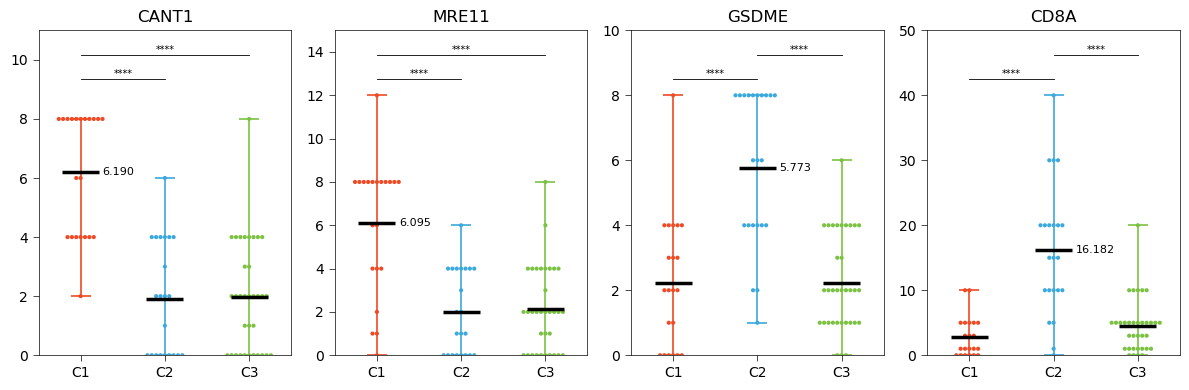

In [24]:
todo = {'CANT1_IRS': (0, 11, 'C1'), 'MRE11_IRS': (0, 15,'C1'), 'GSDME_IRS': (0, 10,'C2'), 'CD8A_per': (0, 50,'C2')}

fig, axes = plt.subplots(1, len(todo), figsize=(12, 4))
for ax, (ID, (lo, hi, g)) in zip(axes, todo.items()):
    panel(ax, matt_data[matt_data['ID'] == ID], lo, hi, label_g=g)
    ax.set_title(ID.split("_")[0])

fig.tight_layout()
plt.show()

In [27]:
out = J(OUTPUTROOT,'fig.4C.scatter.IRS_scores.pdf')
fig.savefig(out, dpi=300, bbox_inches="tight")
print(f"Saving {out}")

write_excel({'fig.4C.data': matt_data}, 'fig.4C.scatter.IRS_scores', outputdir=OUTPUTROOT)

Saving report_c3/fig.4C.scatter.IRS_scores.pdf
  append #1 Sheet [fig.4C.data]
writing 1 .xls @ report_c3/fig.4C.scatter.xlsx


## fig S6G IRS score

In [28]:
import joblib
OBJ = joblib.load(filename='export_c3/fig4_gsea_rf_model_evenly_dis')
OBJ.keys()
# {'dtc':dtc, 
#  'matt_ss':matt_ss, 
#  "matv_ss":matv_ss,
#  "yt":yt
# }

dtc = OBJ['dtc']
matv_ss = OBJ['matv_ss']

yv_true = dtc.predict(matv_ss)
yv_true = pd.Series(yv_true, index=matv_ss.index)
yv_true

P087    C1
P088    C3
P089    C1
        ..
P135    C3
P137    C3
P138    C3
Length: 49, dtype: object

In [29]:
mat_data_ihc_v52 = 'export_c3/fig4_ihc_mat_prospective.dfx'
mat_data_ihc_t77 = "export_c3/fig4_ihc_mat_retrospective.dfx"

glxv = pd.read_csv('external_data/Proteomics52/washed/prt_glx.dfx',sep='\t').rename(columns={"Custom_Label":'tsb'}).set_index('tsb')
glxv = glxv[glxv['Group']!='pCR']
glxv['Group'] = yv_true.loc[glxv.index]
glxv = glxv[['Group']].reset_index()
glxv


,tsb,Group
0,P087,C1
1,P088,C3
2,P089,C1
...,...,...
46,P135,C3
47,P137,C3
48,P138,C3


In [30]:
matv = pd.read_csv(mat_data_ihc_v52,sep='\t',index_col=0).reset_index()

matv = matv.rename(columns={'index': 'tsb', 'CD8_H': 'CD8A_H', 'CD8_per': 'CD8A_per'})
matv['CD8A_per'] = matv['CD8A_per'] * 100

matv_data = (
    matv
    .melt(id_vars='tsb', var_name='ID', value_name='score')
    .assign(type=lambda d: d['ID'].str.split('_').str[1],
            Gene=lambda d: d['ID'].str.split('_').str[0])
    .merge(glxv, on='tsb', how='left')
)
matv_data['Gene'] = pd.Categorical(matv_data['Gene'],
                                   categories=['CANT1', 'MRE11', 'GSDME', 'CD8A'])
matv_data

,tsb,ID,score,type,Gene,Group
0,P087,MRE11_sit,0.0,sit,MRE11,C1
1,P088,MRE11_sit,1.0,sit,MRE11,C3
2,P089,MRE11_sit,2.0,sit,MRE11,C1
...,...,...,...,...,...,...
536,P135,GSDME_IRS,1.0,IRS,GSDME,C3
537,P137,GSDME_IRS,0.0,IRS,GSDME,C3
538,P138,GSDME_IRS,0.0,IRS,GSDME,C3


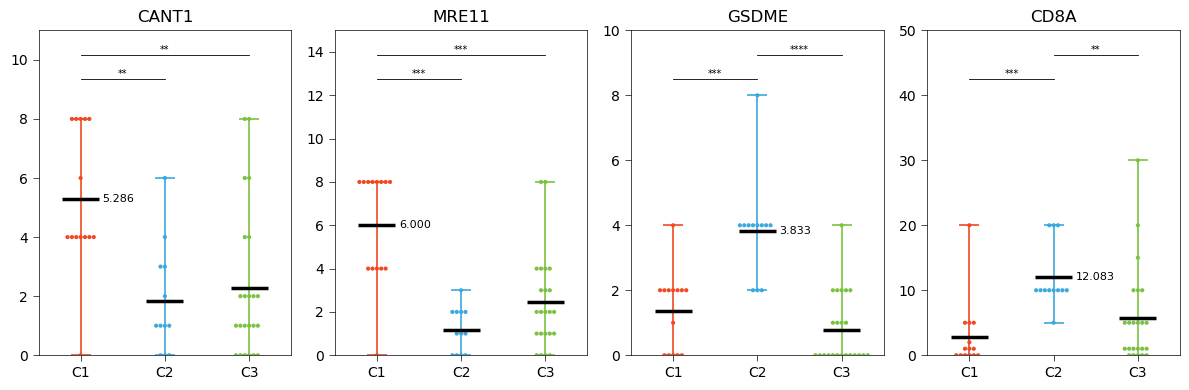

In [31]:
todo = {'CANT1_IRS': (0, 11, 'C1'), 'MRE11_IRS': (0, 15,'C1'), 'GSDME_IRS': (0, 10,'C2'), 'CD8A_per': (0, 50,'C2')}

fig0, axes = plt.subplots(1, len(todo), figsize=(12, 4))
for ax, (ID, (lo, hi, g)) in zip(axes, todo.items()):
    panel(ax, matv_data[matv_data['ID'] == ID], lo, hi, label_g=g)
    ax.set_title(ID.split("_")[0])

fig0.tight_layout()
plt.show()

In [32]:
out = J(OUTPUTROOT,'fig.S6G.scatter.IRS_scores.prospective_cohort.pdf')
fig0.savefig(out, dpi=300, bbox_inches="tight")
print(f"Saving {out}")

write_excel({'fig.S6G.data': matv_data}, 'fig.S6G.scatter.IRS_scores.prospective_cohort', outputdir=OUTPUTROOT)

Saving report_c3/fig.S6G.scatter.IRS_scores.prospective_cohort.pdf
  append #1 Sheet [fig.S6G.data]
writing 1 .xls @ report_c3/fig.S6G.scatter.IRS_scores.xlsx


## fig 4D 4E 4F 4G S6B S6C

In [39]:
glx = pd.read_csv('export_c3/glx_86.dfx',sep='\t')
nonpcr = glx[glx['Group'] != 'pCR']
nonpcr

,tsb,Group,Response
0,P72,C1,non.pCR
1,P10,C1,non.pCR
2,P14,C1,non.pCR
...,...,...,...
74,P01,C3,non.pCR
75,P21,C3,non.pCR
76,P48,C3,non.pCR


In [40]:
yt = nonpcr.set_index('tsb')['Group']
yt

tsb
P72    C1
P10    C1
P14    C1
       ..
P01    C3
P21    C3
P48    C3
Name: Group, Length: 77, dtype: object

In [41]:
# sel4 = ['CD8A', 'GSDME', 'MRE11', 'CANT1']
# matp = pd.read_csv('export_by2_86_pCR_nonpCR/prt_x_7346.dfx',index_col=0,sep='\t')
# mat = matp.loc[sel4,nonpcr['tsb']].T
# mat

matt = pd.read_csv('export_c3/fig4_ihc_mat_retrospective.dfx', sep='\t', index_col=0)
matv = pd.read_csv('export_c3/fig4_ihc_mat_prospective.dfx', sep='\t', index_col=0)

In [43]:
assert (matt.columns == matv.columns).all()
X = matt.loc[yt.index,:]
assert (X.index==yt.index).all()
print(X.shape)
X

(77, 11)


,MRE11_sit,MRE11_per,MRE11_IRS,CANT1_sit,CANT1_per,CANT1_IRS,CD8_per,CD8_H,GSDME_sit,GSDME_per,GSDME_IRS
tsb,,,,,,,,,,,
P72,2.0,4.0,8.0,1.0,4.0,4.0,0.05,2.0,1.0,2.0,2.0
P10,1.0,1.0,1.0,1.0,2.0,2.0,0.00,0.0,1.0,1.0,1.0
P14,2.0,4.0,8.0,2.0,4.0,8.0,0.00,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...
P01,0.0,0.0,0.0,0.0,0.0,0.0,0.05,2.0,1.0,1.0,1.0
P21,2.0,2.0,4.0,0.0,0.0,0.0,0.10,4.0,1.0,2.0,2.0
P48,1.0,1.0,1.0,2.0,1.0,2.0,0.05,2.0,1.0,3.0,3.0


In [ ]:
# Generate synthetic data (replace with your dataset)
features_list = {
     'MRE11':['MRE11_sit','MRE11_per','MRE11_IRS'],
     'CANT1':['CANT1_sit','CANT1_per','CANT1_IRS'],
     'CANT1 MRE11':['MRE11_sit','MRE11_per','MRE11_IRS', 'CANT1_sit','CANT1_per','CANT1_IRS'],
     'CD8A':['CD8_per', 'CD8_H'], 
     'GSDME':['GSDME_sit', 'GSDME_per', 'GSDME_IRS'], 
     'CD8A GSDME':['CD8_per', 'CD8_H', 'GSDME_sit', 'GSDME_per', 'GSDME_IRS']
}
# features_list = {
#      'MRE11':['MRE11_sit','MRE11_per'],
#      'CANT1':['CANT1_sit','CANT1_per'],
#      'CANT1 MRE11':['MRE11_sit','MRE11_per', 'CANT1_sit','CANT1_per'],
#      'CD8A': ['CD8_H'], 
#      'GSDME':['GSDME_IRS'], 
#      'CD8A GSDME':['CD8_H', 'GSDME_IRS']
# }

# Create a 2x3 grid of subplots
fig2, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.ravel()  # Flatten the 2x3 grid to 1D array

roc_data_4defg = {}


for idx, (fea_label, fea) in enumerate(features_list.items()):
    ax = axes[idx]

    # Your existing feature processing code
    if fea_label in ['CANT1','MRE11','CANT1 MRE11']:
        label = 'C1'
    else:
        label = 'C2'
    print(f'  process {label} {fea_label}')
    y = yt.copy()
    rp = {'C1':0,'C2':0,'C3':0}
    rp[label] = 1
    y = y.replace(rp)

    # K-Fold and model training
    kf = KFold(n_splits=5, shuffle=True, random_state=42)
    y_true = []
    y_pred_proba = []

    model = RandomForestClassifier(random_state=42)
    for train_idx, test_idx in kf.split(X[fea]):
        X_train, X_test = X[fea].iloc[train_idx], X[fea].iloc[test_idx]
        y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

        model.fit(X_train, y_train)
        pred_proba = model.predict_proba(X_test)[:, 1]
        y_true.extend(y_test)
        y_pred_proba.extend(pred_proba)

    # Convert to numpy arrays for bootstrapping
    y_true = np.array(y_true)
    y_pred_proba = np.array(y_pred_proba)
    
    # ROC calculation
    fpr, tpr, _ = roc_curve(y_true, y_pred_proba)
    roc_auc = auc(fpr, tpr)
    roc_data_4defg[fea_label] = pd.DataFrame({'fpr': fpr, 'tpr': tpr})
    
    # Bootstrap confidence interval
    n_bootstraps = 1000
    bootstrapped_scores = []
    rng = np.random.RandomState(42)
    
    for _ in range(n_bootstraps):
        indices = rng.choice(len(y_pred_proba), len(y_pred_proba), replace=True)
        if len(np.unique(y_true[indices])) < 2:
            continue  # Skip if only one class present
        
        score = roc_auc_score(y_true[indices], y_pred_proba[indices])
        bootstrapped_scores.append(score)
    
    # Calculate confidence interval
    if len(bootstrapped_scores) > 0:
        ci_lower = np.percentile(bootstrapped_scores, 2.5)
        ci_upper = np.percentile(bootstrapped_scores, 97.5)
    else:
        ci_lower = ci_upper = roc_auc  # Fallback if no valid bootstrap samples

    # Plot on specific subplot
    ax.plot(fpr, tpr, color=COL_ANNO[label], lw=2, 
            label=f'AUC = {roc_auc:.2f} (95% CI {ci_lower:.2f}-{ci_upper:.2f})')
    ax.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
    ax.set_xlabel('False Positive Rate')
    ax.set_ylabel('True Positive Rate')
    ax.set_title(f'{fea_label}')
    ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [45]:
fig2.savefig(J(OUTPUTROOT,'fig.4D.4E.4F.4G.IHC_maker_AUC.pdf'))
write_excel({"X":X, 'y':yt}, 'fig.4D.4E.4F.4G.IHC_maker_AUC_input.xlsx' , outputdir=OUTPUTROOT)
write_excel(roc_data_4defg, 'fig.4D.4E.4F.4G.IHC_maker_AUC_output.xlsx', outputdir=OUTPUTROOT)


  append #1 Sheet [X]
covert y: <class 'pandas.core.series.Series'> -> <class 'pandas.core.frame.DataFrame'>
  append #2 Sheet [y]
writing 1 .xls @ report_c3/fig.4D.4E.4F.4G.IHC_maker_AUC_input.xlsx
  append #1 Sheet [MRE11]
  append #2 Sheet [CANT1]
  append #3 Sheet [CANT1 MRE11]
  append #4 Sheet [CD8A]
  append #5 Sheet [GSDME]
  append #6 Sheet [CD8A GSDME]
writing 1 .xls @ report_c3/fig.4D.4E.4F.4G.IHC_maker_AUC_output.xlsx


### fig S6B S6C

In [27]:
glx = pd.read_csv('export_c3/glx_86.dfx',sep='\t')
colData = glx[glx['Response']!='pCR']
colData

,tsb,Group,Response
0,P72,C1,non.pCR
1,P10,C1,non.pCR
2,P14,C1,non.pCR
...,...,...,...
74,P01,C3,non.pCR
75,P21,C3,non.pCR
76,P48,C3,non.pCR


In [28]:
prt = pd.read_csv('export_by2_86_pCR_nonpCR/prt_x_7346.dfx', index_col=0, sep='\t')
prt = prt.loc[:,colData['tsb']]
prt

,P72,P10,P14,P56,P16,P52,P47,P80,P70,P71,...,P09,P40,P15,P26,P50,P04,P02,P01,P21,P48
A1BG,-0.450353,-0.176356,-0.167464,-0.098216,-0.390001,-0.021070,-0.073197,0.280976,-0.236020,-0.062418,...,-0.188679,-0.215204,0.107161,0.062331,0.163193,0.002907,0.293907,0.287177,0.460217,0.127303
A2M,-0.734465,-0.384376,-0.791212,-0.850223,-0.699117,-0.440579,0.195193,0.478877,0.210634,-0.296470,...,-0.250644,-0.416589,0.072189,0.017448,0.244907,0.030337,0.409493,0.002230,-0.160088,0.376542
NAT1,-0.406279,0.933905,0.164351,0.806863,-0.080495,-0.238646,0.541111,-0.086729,0.120557,-0.109218,...,0.040502,-0.077236,0.170163,-0.020117,-0.144154,0.290496,0.143030,-0.026872,-0.039922,-0.083034
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
MMP24OS,0.010281,-0.099396,0.359364,0.030994,0.077816,0.208879,-0.056948,-0.109430,-0.036508,-0.086448,...,-0.097899,-0.112208,-0.392279,-0.158362,0.108567,-0.765025,-0.044449,-0.621264,-0.152615,0.050141
PIGBOS1,-0.100793,0.080744,0.024404,-0.293287,-0.195656,0.158657,0.085631,1.118059,-0.137161,0.044224,...,0.233400,-0.266756,-0.068058,0.117906,0.644079,0.126717,-0.110429,-0.049885,-0.106468,-0.067353
C11orf98,0.486610,0.322009,0.181039,-0.009502,0.305777,0.096638,-0.012016,0.041043,0.092582,0.274839,...,-0.025363,-0.162897,-0.054872,-0.136312,0.053062,0.059450,0.175422,0.004817,0.132714,-0.000527


In [33]:
X = prt.loc[['CANT1','MRE11','CD8A','GSDME']].T
X

,CANT1,MRE11,CD8A,GSDME
P72,0.635984,0.030908,-0.099113,-0.285354
P10,0.229122,0.262279,0.092169,0.016769
P14,0.463078,0.063239,-0.240947,0.295463
...,...,...,...,...
P01,-0.066184,-0.013484,0.066756,-0.039891
P21,-0.204357,0.058111,0.021309,-0.031734
P48,-0.245483,-0.034762,0.175233,0.026668


In [34]:
yt = colData.set_index('tsb')['Group']
yt

tsb
P72    C1
P10    C1
P14    C1
       ..
P01    C3
P21    C3
P48    C3
Name: Group, Length: 77, dtype: object

In [ ]:
# Generate synthetic data (replace with your dataset)
features_list = {
     'CANT1 MRE11':['MRE11','CANT1'],
     'CD8A GSDME':['CD8A','GSDME'],
}
# features_list = {
#      'MRE11':['MRE11_sit','MRE11_per'],
#      'CANT1':['CANT1_sit','CANT1_per'],
#      'CANT1 MRE11':['MRE11_sit','MRE11_per', 'CANT1_sit','CANT1_per'],
#      'CD8A': ['CD8_H'], 
#      'GSDME':['GSDME_IRS'], 
#      'CD8A GSDME':['CD8_H', 'GSDME_IRS']
# }

# Create a 2x3 grid of subplots
fig3, axes = plt.subplots(1, 2, figsize=(10, 5))
axes = axes.ravel()  # Flatten the 2x3 grid to 1D array

roc_data_4defg = {}


for idx, (fea_label, fea) in enumerate(features_list.items()):
    ax = axes[idx]

    # Your existing feature processing code
    if fea_label in ['CANT1','MRE11','CANT1 MRE11']:
        label = 'C1'
    else:
        label = 'C2'
    print(f'  process {label} {fea_label}')
    y = yt.copy()
    rp = {'C1':0,'C2':0,'C3':0}
    rp[label] = 1
    y = y.replace(rp)

    # K-Fold and model training
    kf = KFold(n_splits=5, shuffle=True, random_state=42)
    y_true = []
    y_pred_proba = []

    model = RandomForestClassifier(random_state=42)
    for train_idx, test_idx in kf.split(X[fea]):
        X_train, X_test = X[fea].iloc[train_idx], X[fea].iloc[test_idx]
        y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

        model.fit(X_train, y_train)
        pred_proba = model.predict_proba(X_test)[:, 1]
        y_true.extend(y_test)
        y_pred_proba.extend(pred_proba)

    # Convert to numpy arrays for bootstrapping
    y_true = np.array(y_true)
    y_pred_proba = np.array(y_pred_proba)
    
    # ROC calculation
    fpr, tpr, _ = roc_curve(y_true, y_pred_proba)
    roc_auc = auc(fpr, tpr)
    roc_data_4defg[fea_label] = pd.DataFrame({'fpr': fpr, 'tpr': tpr})
    
    # Bootstrap confidence interval
    n_bootstraps = 1000
    bootstrapped_scores = []
    rng = np.random.RandomState(42)
    
    for _ in range(n_bootstraps):
        indices = rng.choice(len(y_pred_proba), len(y_pred_proba), replace=True)
        if len(np.unique(y_true[indices])) < 2:
            continue  # Skip if only one class present
        
        score = roc_auc_score(y_true[indices], y_pred_proba[indices])
        bootstrapped_scores.append(score)
    
    # Calculate confidence interval
    if len(bootstrapped_scores) > 0:
        ci_lower = np.percentile(bootstrapped_scores, 2.5)
        ci_upper = np.percentile(bootstrapped_scores, 97.5)
    else:
        ci_lower = ci_upper = roc_auc  # Fallback if no valid bootstrap samples

    # Plot on specific subplot
    ax.plot(fpr, tpr, color=COL_ANNO[label], lw=2, 
            label=f'AUC = {roc_auc:.2f} (95% CI {ci_lower:.2f}-{ci_upper:.2f})')
    ax.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
    ax.set_xlabel('False Positive Rate')
    ax.set_ylabel('True Positive Rate')
    ax.set_title(f'{fea_label}')
    ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [38]:
fig3.savefig(J(OUTPUTROOT,'fig.S6B.S6C.Prt_abundance_IHC_maker_AUC.pdf'))
write_excel({"X":X, 'y':yt}, 'fig.S6B.S6C.Prt_abundance_IHC_maker_input.xlsx' , outputdir=OUTPUTROOT)
write_excel(roc_data_4defg, 'fig.S6B.S6C.Prt_abundance_IHC_maker_output.xlsx', outputdir=OUTPUTROOT)


  append #1 Sheet [X]
covert y: <class 'pandas.core.series.Series'> -> <class 'pandas.core.frame.DataFrame'>
  append #2 Sheet [y]
writing 1 .xls @ report_c3/fig.S6B.S6C.Prt_abundance_IHC_maker_input.xlsx
  append #1 Sheet [CANT1 MRE11]
  append #2 Sheet [CD8A GSDME]
writing 1 .xls @ report_c3/fig.S6B.S6C.Prt_abundance_IHC_maker_output.xlsx


## fig S6H prospective cohort (n=49)

In [39]:
glxt = pd.read_csv('export_c3/glx_86.dfx',sep='\t').rename(columns={'tsb':"Custom_Label"})
glxt = glxt[glxt['Group']!='pCR'].reset_index(drop=True)
nonpcr_t = glxt['Custom_Label']
glxt['source'] = 'train86'
matt_hm = pd.read_csv('export_by2_86_pCR_nonpCR/prt_ssGSEA_hm.dfx',sep='\t')
matt_im = pd.read_csv('export_by2_86_pCR_nonpCR/prt_ssGSEA_immune.dfx',sep='\t')
matt = pd.concat([matt_hm, matt_im])
matt = matt.loc[:,glxt['Custom_Label']]
matt_ss = standarize(matt)
matt_ss

,HALLMARK_TNFA_SIGNALING_VIA_NFKB,HALLMARK_HYPOXIA,HALLMARK_CHOLESTEROL_HOMEOSTASIS,HALLMARK_MITOTIC_SPINDLE,HALLMARK_WNT_BETA_CATENIN_SIGNALING,HALLMARK_TGF_BETA_SIGNALING,HALLMARK_IL6_JAK_STAT3_SIGNALING,HALLMARK_DNA_REPAIR,HALLMARK_G2M_CHECKPOINT,HALLMARK_APOPTOSIS,...,Monocyte,Natural killer cell,Natural killer T cell,Neutrophil,Plasmacytoid dendritic cell,Regulatory T cell,T follicular helper cell,Type 1 T helper cell,Type 17 T helper cell,Type 2 T helper cell
P72,-0.852969,-0.807859,2.841836,-2.165969,-1.433275,-0.277025,-1.085056,1.977283,2.133645,-0.574746,...,0.767630,-1.305247,-1.258421,-1.033498,0.498123,-1.760289,-0.112277,-1.964240,-1.506620,-2.263889
P10,-1.440097,-0.448208,0.621753,-0.881378,-1.475931,1.563537,-0.266138,0.995168,0.223760,-0.283356,...,0.698230,-1.685477,0.161159,-1.246160,1.314077,-0.669843,-1.655700,-0.313686,-1.106294,-1.821901
P14,-1.105704,-3.045652,0.743002,-1.077329,-0.444694,0.371055,-0.440861,0.239344,1.099192,-2.040085,...,0.927218,-0.773782,-2.201409,-1.813741,0.283886,-1.134669,-0.047122,-1.417866,-0.271039,-0.136589
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
P01,-0.902662,0.099330,0.231725,-1.295932,0.590862,-1.521677,-0.088727,0.403991,0.548646,0.892272,...,-2.572132,0.563526,0.676447,1.137281,0.187191,-0.262616,0.889299,0.385663,-0.023857,1.035726
P21,-0.963049,-0.308621,-1.239494,0.683048,1.224607,-1.117368,-0.380631,0.450699,-0.107632,-0.845505,...,-1.007844,-0.631081,-1.313337,0.441823,-0.803702,-1.377661,0.369029,0.160726,0.285574,0.331064
P48,1.887348,0.382345,0.152482,0.972673,1.962303,1.218861,-0.510473,-0.371868,-0.258315,0.976290,...,0.636608,0.224964,0.972538,-1.719642,-0.053808,0.535272,-0.818111,1.054449,-0.475308,2.162875


In [40]:
glxv = pd.read_csv('external_data/Proteomics52/washed/prt_glx.dfx',sep='\t')
glxv = glxv[glxv['Group'] !='pCR'].reset_index(drop=True)
nonpcr_v = glxv['Custom_Label']
matv_hm = pd.read_csv('external_data/Proteomics52/washed/prt_ssgsea_hm.dfx',sep='\t')
matv_im = pd.read_csv('external_data/Proteomics52/washed/prt_ssgsea_immune.dfx',sep='\t')
matv = pd.concat([matv_hm, matv_im])
matv = matv.loc[matt.index,matv.columns.isin(nonpcr_v)]
from sklearn.preprocessing import StandardScaler
def standarize(mat):
    """
    mat: index are ssGSEA terms, columns are patients
    Returns:
        StandardScaler scaled dataframe, index are Patients, columns are ssGSEA terms
    """
    mt = mat.T
    x = StandardScaler().fit_transform(mt)
    res = pd.DataFrame(x, index = mt.index, columns=mt.columns)
    return res
matv_ss = standarize(matv)
matv_ss

,HALLMARK_TNFA_SIGNALING_VIA_NFKB,HALLMARK_HYPOXIA,HALLMARK_CHOLESTEROL_HOMEOSTASIS,HALLMARK_MITOTIC_SPINDLE,HALLMARK_WNT_BETA_CATENIN_SIGNALING,HALLMARK_TGF_BETA_SIGNALING,HALLMARK_IL6_JAK_STAT3_SIGNALING,HALLMARK_DNA_REPAIR,HALLMARK_G2M_CHECKPOINT,HALLMARK_APOPTOSIS,...,Monocyte,Natural killer cell,Natural killer T cell,Neutrophil,Plasmacytoid dendritic cell,Regulatory T cell,T follicular helper cell,Type 1 T helper cell,Type 17 T helper cell,Type 2 T helper cell
P087,-0.133266,0.986611,-0.677305,0.193466,0.166603,-0.867315,-2.153201,0.100729,0.585779,-0.608514,...,-0.011225,-1.076849,-0.145429,-0.932165,-1.066639,0.165721,0.001987,-0.948242,-0.905716,0.700878
P088,-0.032212,1.238137,-0.752048,0.171244,-0.740046,-1.074603,-1.843494,0.447254,0.909224,0.086776,...,-0.232329,-0.950319,1.031173,-0.910876,-1.523191,1.546003,0.372701,-0.652174,-0.505707,0.604338
P089,0.779898,0.680767,-1.034675,0.181467,-0.821811,-1.493379,-1.945434,-0.117838,0.261844,0.940749,...,-0.280551,-1.851204,-0.274841,0.965340,-2.127217,0.837964,-0.929295,-0.139098,-0.930594,0.211528
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
P135,-0.554209,-0.855388,1.145983,-0.015412,1.541169,0.096159,0.005882,-0.327989,-0.959578,-1.345275,...,-0.263490,-0.244633,-0.266865,-0.372404,-1.055134,-0.039427,1.454411,-0.323199,0.586413,-0.866908
P137,-0.018506,0.338860,0.264176,0.700913,0.774704,1.309713,-1.028389,0.675263,0.426152,-0.676358,...,-0.134684,0.321080,-0.825888,-0.349545,-0.383300,-0.697291,0.868451,0.670332,-0.292511,-1.236084
P138,0.172343,-0.953167,-1.499110,-0.437923,-1.145818,1.053363,-0.685743,-0.298711,0.590383,-1.294831,...,0.313022,-2.260205,-1.311015,0.471970,0.284899,1.787546,-0.743367,1.106857,-0.065374,0.088453


In [41]:
import joblib
OBJ = joblib.load(filename='export_c3/fig4_gsea_rf_model_evenly_dis')
OBJ.keys()
# {'dtc':dtc, 
#  'matt_ss':matt_ss, 
#  "matv_ss":matv_ss,
#  "yt":yt
# }

dict_keys(['dtc', 'xtest', 'ytest', 'matt_ss', 'matv_ss'])

In [42]:
dtc = OBJ['dtc']
matv_ss = OBJ['matv_ss']
matt_ss = OBJ['matt_ss']
dtc

RandomForestClassifier()

In [43]:
yv_true = dtc.predict(matv_ss)
yv_true

array(['C1', 'C3', 'C1', 'C1', 'C2', 'C1', 'C2', 'C3', 'C3', 'C3', 'C2',
       'C2', 'C3', 'C2', 'C3', 'C3', 'C2', 'C2', 'C1', 'C3', 'C3', 'C1',
       'C1', 'C3', 'C1', 'C3', 'C3', 'C1', 'C3', 'C3', 'C2', 'C1', 'C3',
       'C1', 'C2', 'C3', 'C2', 'C3', 'C3', 'C3', 'C1', 'C2', 'C1', 'C1',
       'C3', 'C2', 'C3', 'C3', 'C3'], dtype=object)

In [44]:
matt = pd.read_csv('export_c3/fig4_ihc_mat_retrospective.dfx', sep='\t', index_col=0)
matv = pd.read_csv('export_c3/fig4_ihc_mat_prospective.dfx', sep='\t', index_col=0)

In [45]:
assert (matt.columns == matv.columns).all()
Y = pd.Series(yv_true, index=matv_ss.index)
X = matv.loc[Y.index,:]
assert (X.index==Y.index).all()
X.shape

(49, 11)

In [ ]:
# Generate synthetic data (replace with your dataset)
features_list = {
     'MRE11':['MRE11_sit','MRE11_per','MRE11_IRS'],
     'CANT1':['CANT1_sit','CANT1_per','CANT1_IRS'],
     # 'CANT1 MRE11':['MRE11_sit','MRE11_per','MRE11_IRS', 'CANT1_sit','CANT1_per','CANT1_IRS'],
     'CD8A':['CD8_per', 'CD8_H'], 
     'GSDME':['GSDME_sit', 'GSDME_per', 'GSDME_IRS'], 
     # 'CD8A GSDME':['CD8_per', 'CD8_H', 'GSDME_sit', 'GSDME_per', 'GSDME_IRS']
}
# features_list = {
#      'MRE11':['MRE11_sit','MRE11_per'],
#      'CANT1':['CANT1_sit','CANT1_per'],
#      'CANT1 MRE11':['MRE11_sit','MRE11_per', 'CANT1_sit','CANT1_per'],
#      'CD8A': ['CD8_H'], 
#      'GSDME':['GSDME_IRS'], 
#      'CD8A GSDME':['CD8_H', 'GSDME_IRS']
# }

# Create a 2x3 grid of subplots
fig3, axes = plt.subplots(2, 2, figsize=(10, 10))
axes = axes.ravel()  # Flatten the 2x3 grid to 1D array

roc_data_s5h = {}


for idx, (fea_label, fea) in enumerate(features_list.items()):
    ax = axes[idx]

    # Your existing feature processing code
    if fea_label in ['CANT1','MRE11','CANT1 MRE11']:
        label = 'C1'
    else:
        label = 'C2'
    print(f'  process {label} {fea_label}')
    y = Y.copy()
    rp = {'C1':0,'C2':0,'C3':0}
    rp[label] = 1
    y = y.replace(rp)

    # K-Fold and model training
    kf = KFold(n_splits=5, shuffle=True, random_state=5)
    y_true = []
    y_pred_proba = []

    model = RandomForestClassifier(random_state=42)
    for train_idx, test_idx in kf.split(X[fea]):
        X_train, X_test = X[fea].iloc[train_idx], X[fea].iloc[test_idx]
        y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

        model.fit(X_train, y_train)
        pred_proba = model.predict_proba(X_test)[:, 1]
        y_true.extend(y_test)
        y_pred_proba.extend(pred_proba)

    # Convert to numpy arrays for bootstrapping
    y_true = np.array(y_true)
    y_pred_proba = np.array(y_pred_proba)
    
    # ROC calculation
    fpr, tpr, _ = roc_curve(y_true, y_pred_proba)
    roc_auc = auc(fpr, tpr)
    roc_data_s5h[fea_label] = pd.DataFrame({'fpr': fpr, 'tpr': tpr})
    
    # Bootstrap confidence interval
    n_bootstraps = 1000
    bootstrapped_scores = []
    rng = np.random.RandomState(42)
    
    for _ in range(n_bootstraps):
        indices = rng.choice(len(y_pred_proba), len(y_pred_proba), replace=True)
        if len(np.unique(y_true[indices])) < 2:
            continue  # Skip if only one class present
        
        score = roc_auc_score(y_true[indices], y_pred_proba[indices])
        bootstrapped_scores.append(score)
    
    # Calculate confidence interval
    if len(bootstrapped_scores) > 0:
        ci_lower = np.percentile(bootstrapped_scores, 2.5)
        ci_upper = np.percentile(bootstrapped_scores, 97.5)
    else:
        ci_lower = ci_upper = roc_auc  # Fallback if no valid bootstrap samples

    # Plot on specific subplot
    ax.plot(fpr, tpr, color=COL_ANNO[label], lw=2, 
            label=f'AUC = {roc_auc:.2f} (95% CI {ci_lower:.2f}-{ci_upper:.2f})')
    ax.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
    ax.set_xlabel('False Positive Rate')
    ax.set_ylabel('True Positive Rate')
    ax.set_title(f'{fea_label}')
    ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [47]:
fig3.savefig(J(OUTPUTROOT,'fig.S6H.IHC_maker_AUC_prospective_cohort.pdf'))
write_excel(roc_data_s5h, 'fig.S6H.IHC_maker_AUC_prospective_cohort', outputdir=OUTPUTROOT)

  append #1 Sheet [MRE11]
  append #2 Sheet [CANT1]
  append #3 Sheet [CD8A]
  append #4 Sheet [GSDME]
writing 1 .xls @ report_c3/fig.S6H.xlsx


## fig S6A
**Fig S6A — manually generated.** This panel was drawn manually with external tools; there is no plotting code in this repository.

## Fig S6D S6E ROC model Metrics

In [48]:
import joblib
OBJ = joblib.load(filename='export_c3/fig4_gsea_rf_model_evenly_dis')
OBJ.keys()
# {'dtc':dtc, 
#  'matt_ss':matt_ss, 
#  "matv_ss":matv_ss,
#  "yt":yt
# }

dict_keys(['dtc', 'xtest', 'ytest', 'matt_ss', 'matv_ss'])

In [49]:
dtc = OBJ['dtc']
matt_ss = OBJ['matt_ss']
matv_ss = OBJ['matv_ss']
xtest = OBJ['xtest']
ytest = OBJ['ytest']

yv_true = dtc.predict(matv_ss)
yv_true = pd.Series(yv_true, index=matv_ss.index)
yv_true

P087    C1
P088    C3
P089    C1
        ..
P135    C3
P137    C3
P138    C3
Length: 49, dtype: object

In [50]:
glx = pd.read_csv('export_c3/glx_86.dfx',sep='\t')
colData = glx[glx['Response']!='pCR']
colData

,tsb,Group,Response
0,P72,C1,non.pCR
1,P10,C1,non.pCR
2,P14,C1,non.pCR
...,...,...,...
74,P01,C3,non.pCR
75,P21,C3,non.pCR
76,P48,C3,non.pCR


In [51]:
yt = colData.set_index('tsb')['Group']
yt

tsb
P72    C1
P10    C1
P14    C1
       ..
P01    C3
P21    C3
P48    C3
Name: Group, Length: 77, dtype: object

In [52]:
class_names = ['C1','C2','C3']
colors = cycle(['#F04923', '#3BA9DD','#7CC242'])

In [53]:
ypred = dtc.predict(xtest)
cm = confusion_matrix(ytest,ypred)
cm = pd.DataFrame(cm, index=dtc.classes_,columns=dtc.classes_)
cm.index.name = 'GroundTruth'
PPV = cm.apply(lambda x: x[x.name] / x.sum(),0)[['C1','C2']].mean()
print(f"PPV = {PPV}")
cm

PPV = 0.9375


,C1,C2,C3
GroundTruth,,,
C1,5,1,0
C2,0,7,0
C3,0,0,11


In [54]:
ypred = dtc.predict(matt_ss)
cm = confusion_matrix(yt,ypred)
cm = pd.DataFrame(cm, index=dtc.classes_,columns=dtc.classes_)
cm.index.name = 'GroundTruth'
PPV = cm.apply(lambda x: x[x.name] / x.sum(),0)[['C1','C2']].mean()
print(f"PPV = {PPV}")
cm

PPV = 0.9782608695652174


,C1,C2,C3
GroundTruth,,,
C1,20,1,0
C2,0,22,0
C3,0,0,34


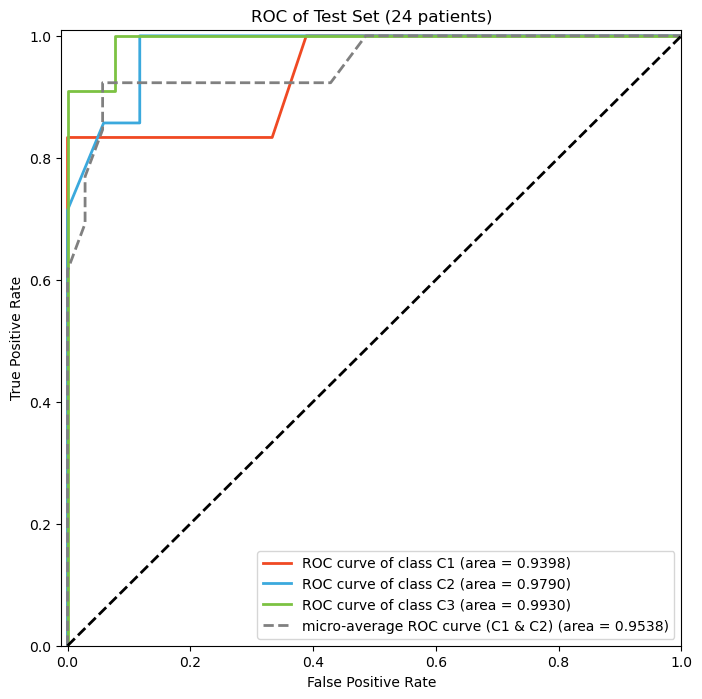

In [56]:
fig_test = plot_auc_3plus(dtc, xtest, ytest, fig_title=f'ROC of Test Set ({len(xtest)} patients)')

In [57]:
fig_test.set_size_inches(6, 6)
fig_test.savefig(J(OUTPUTROOT, 'fig.S6D.ROC_test_set.pdf'))
write_excel(fig_test.roc_data, 'fig.S6D.ROC_test_set', outputdir=OUTPUTROOT)

  append #1 Sheet [C1]
  append #2 Sheet [C2]
  append #3 Sheet [C3]
  append #4 Sheet [micro]
writing 1 .xls @ report_c3/fig.S6D.xlsx


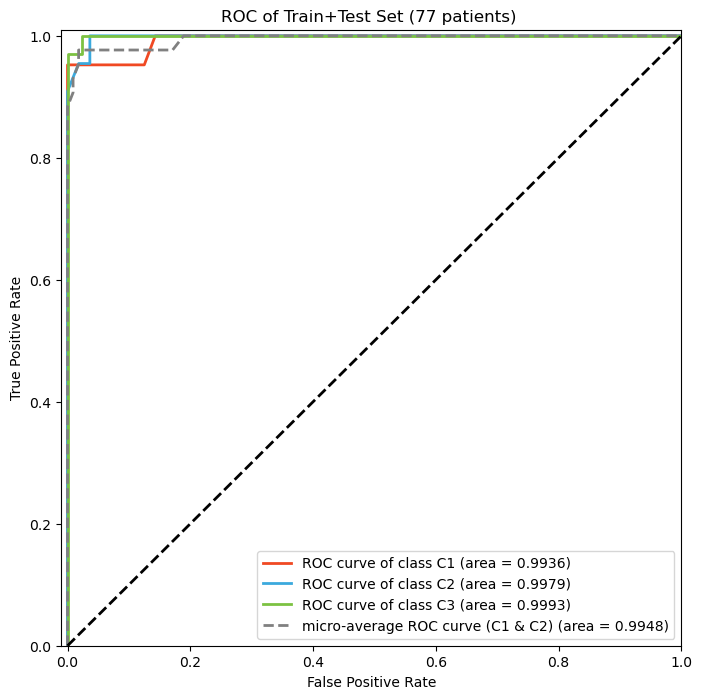

In [58]:
fig_train_test = plot_auc_3plus(dtc, matt_ss, yt, fig_title=f'ROC of Train+Test Set ({len(matt_ss)} patients) ')

In [59]:
fig_train_test.set_size_inches(6, 6)
fig_train_test.savefig(J(OUTPUTROOT, 'fig.S6E.ROC_train_test_set.pdf'))
write_excel(fig_train_test.roc_data, 'fig.S6E.ROC_train_test_set', outputdir=OUTPUTROOT)

  append #1 Sheet [C1]
  append #2 Sheet [C2]
  append #3 Sheet [C3]
  append #4 Sheet [micro]
writing 1 .xls @ report_c3/fig.S6E.xlsx


## fig 4I 4J classify

In [ ]:
class Model:
#     def __init__(self, X, y):
    def predict(self, X):
        c1 = X['MRE11_IRS'] + X['CANT1_IRS']
        c2 = X['CD8_H'] + X['GSDME_IRS']
        y = pd.Series('C3', index=X.index)
        y[(c1<=8) & (c2>=8)] = 'C2'
        y[c1 > 8] = 'C1'
        return y
ihc_model = Model()

from sklearn.metrics import confusion_matrix, cohen_kappa_score
from matplotlib.gridspec import GridSpec
import pandas as pd
import numpy as np

classes = ['C1','C2','C3']

def gen_cm(res):
    # Example data (replace with your actual data)
    y_true = res['y_true']
    y_pred = res['y_pred']
    classes = ['C1','C2','C3']  # Class labels in desired order

    # Generate confusion matrix
    cm = confusion_matrix(y_true, y_pred, labels=classes)
    n_samples = cm.sum()

    # Convert to DataFrame for clarity
    cm_df = pd.DataFrame(cm, 
                         index=[f'True {cls}' for cls in classes], 
                         columns=[f'Pred {cls}' for cls in classes])

    print("Confusion Matrix:")
    return cm, cm_df


def gen_report_metrics(res, cm):
    # Initialize DataFrame to store metrics
    y_true = res['y_true']
    y_pred = res['y_pred']
    report = []
    n_samples = cm.sum()

    for idx, cls in enumerate(classes):
        # Calculate PPV, Sensitivity, Specificity
        tp = cm[idx, idx]
        fp = cm[:, idx].sum() - tp
        fn = cm[idx, :].sum() - tp
        tn = cm.sum() - (tp + fp + fn)

        ppv = tp / (tp + fp) if (tp + fp) != 0 else 0.0
        sensitivity = tp / (tp + fn) if (tp + fn) != 0 else 0.0
        specificity = tn / (tn + fp) if (tn + fp) != 0 else 0.0

        # Calculate class-specific Cohen's Kappa (binary one-vs-rest)
        y_true_bin = (y_true == cls).astype(int)
        y_pred_bin = (y_pred == cls).astype(int)
        kappa = cohen_kappa_score(y_true_bin, y_pred_bin)

        # Calculate Kappa CI for binary case
        cm_bin = confusion_matrix(y_true_bin, y_pred_bin)
        n_bin = cm_bin.sum()
        if n_bin > 0:
            p_o = np.trace(cm_bin) / n_bin
            sum_true = cm_bin.sum(axis=1)
            sum_pred = cm_bin.sum(axis=0)
            p_e = np.sum((sum_true / n_bin) * (sum_pred / n_bin))

            if p_e != 1:
                var_kappa = (p_o * (1 - p_o)) / (n_bin * (1 - p_e)**2)
                se = np.sqrt(var_kappa)
                ci_lower = kappa - 1.96 * se
                ci_upper = kappa + 1.96 * se
            else:
                ci_lower = ci_upper = kappa
        else:
            ci_lower = ci_upper = 0.0

        # Add to report
        report.append({
            'Class': cls,
            'PPV': round(ppv, 3),
            'Sensitivity': round(sensitivity, 3),
            'Specificity': round(specificity, 3),
            'Kappa': round(kappa, 3),
            'Kappa CI': f"[{ci_lower:.3f}, {ci_upper:.3f}]"
        })

    # 2. Macro averages for PPV, Sensitivity, Specificity
    macro_avg = {
        'Class': 'Macro Avg',
        'PPV': round(np.mean([x['PPV'] for x in report]), 3),
        'Sensitivity': round(np.mean([x['Sensitivity'] for x in report]), 3),
        'Specificity': round(np.mean([x['Specificity'] for x in report]), 3),
        'Kappa': None,
        'Kappa CI': None
    }

    # 3. Overall Cohen's Kappa (multi-class) and CI
    overall_kappa = cohen_kappa_score(y_true, y_pred)
    p_o = np.trace(cm) / n_samples
    sum_true = cm.sum(axis=1)
    sum_pred = cm.sum(axis=0)
    p_e = np.sum((sum_true / n_samples) * (sum_pred / n_samples))

    if p_e != 1:
        var_kappa = (p_o * (1 - p_o)) / (n_samples * (1 - p_e)**2)
        se = np.sqrt(var_kappa)
        ci_lower = overall_kappa - 1.96 * se
        ci_upper = overall_kappa + 1.96 * se
    else:
        ci_lower = ci_upper = overall_kappa

    overall_row = {
        'Class': 'Overall',
        'PPV': None,
        'Sensitivity': None,
        'Specificity': None,
        'Kappa': round(overall_kappa, 3),
        'Kappa CI': f"[{ci_lower:.3f}, {ci_upper:.3f}]"
    }

    # Combine all results
    report_df = pd.DataFrame(report + [macro_avg, overall_row])
    report_df.set_index('Class', inplace=True)

    return report_df

def avg_ppv(cm_df):
    """Mean PPV (%) of C1 and C2; cm_df rows = reference class, columns = IHC-predicted class."""
    ppv = [cm_df.iloc[i, i] / cm_df.iloc[:, i].sum() for i in range(2)]
    return round(float(np.mean(ppv)) * 100, 1)


In [61]:
## plot function

DEFAULT_COLORS = ["#EE3B2C", "#2FA9E0", "#4CAF3C"]  # red, blue, green

# ------------------------------------------------------------------
# Panel 1: left horizontal stacked bar (row-wise fraction %)
# ------------------------------------------------------------------
def plot_horizontal_bar(cm_df, colors=None, row_labels=None, ax=None):
    """Stacked horizontal bar chart of row-normalized fractions (%).

    cm_df : DataFrame, rows = true class, cols = predicted class
    """
    n_class = cm_df.shape[0]
    colors = colors or DEFAULT_COLORS
    row_labels = row_labels or [f"Protein-C{i+1}" for i in range(n_class)]

    if ax is None:
        fig, ax = plt.subplots(figsize=(5, 3.5))
    else:
        fig = ax.figure

    n_total = cm_df.sum(axis=1)
    frac = cm_df.div(n_total, axis=0) * 100

    y_pos = np.arange(n_class)[::-1]  # top row = first class
    left = np.zeros(n_class)
    for j, col in enumerate(cm_df.columns):
        vals = frac[col].values
        ax.barh(y_pos, vals, left=left, color=colors[j], height=0.6,
                 edgecolor="white")
        left += vals

    ax.set_yticks(y_pos)
    ax.set_yticklabels(row_labels)
    ax.set_xlim(0, 100)
    ax.set_xlabel("Fraction (%)")
    ax.xaxis.set_label_position("top")
    ax.xaxis.tick_top()
    for spine in ["left", "right", "bottom"]:
        ax.spines[spine].set_visible(False)

    return fig, ax

# ------------------------------------------------------------------
# Panel 2: middle confusion matrix grid (raw counts)
# ------------------------------------------------------------------
def plot_confusion_grid(cm_df, col_labels=None, ax=None):
    """Draws the raw confusion matrix counts as a simple bordered grid."""
    n_class = cm_df.shape[0]
    col_labels = col_labels or list(cm_df.columns)

    if ax is None:
        fig, ax = plt.subplots(figsize=(3.5, 3.5))
    else:
        fig = ax.figure

    ax.set_xlim(0, n_class)
    ax.set_ylim(0, n_class)
    ax.set_aspect("equal")
    ax.invert_yaxis()

    for i in range(n_class):
        for j in range(n_class):
            ax.text(j + 0.5, i + 0.5, str(cm_df.iloc[i, j]),
                     ha="center", va="center", fontsize=13, fontweight="bold")

    for k in range(n_class + 1):
        ax.axhline(k, color="black", lw=1)
        ax.axvline(k, color="black", lw=1)

    ax.set_xticks(np.arange(n_class) + 0.5)
    ax.set_xticklabels(col_labels)
    ax.xaxis.tick_top()
    ax.set_yticks([])
    ax.tick_params(length=0)
    for spine in ax.spines.values():
        spine.set_visible(False)

    return fig, ax

# ------------------------------------------------------------------
# Panel 3: right vertical bar chart of kappa + CI error bars
# ------------------------------------------------------------------
def plot_kappa_bar(kappa_df, colors=None, ax=None, legend=True):
    """kappa_df needs columns: label, kappa, ci_lo, ci_hi.
    Include an 'Overall' row (typically colored gray) if desired.
    """
    n = len(kappa_df)
    colors = colors or (DEFAULT_COLORS + ["#C9C9C9"])[:n]

    if ax is None:
        fig, ax = plt.subplots(figsize=(3.5, 3.5))
    else:
        fig = ax.figure

    x = np.arange(n)
    err_low = kappa_df["kappa"] - kappa_df["ci_lo"]
    err_high = kappa_df["ci_hi"] - kappa_df["kappa"]

    ax.bar(x, kappa_df["kappa"], yerr=[err_low, err_high], color=colors,
            edgecolor="black", linewidth=0.8, capsize=4,
            error_kw=dict(lw=1.2, capthick=1.2))
    ax.set_xticks(x)
    ax.set_xticklabels(kappa_df["label"], rotation=30, ha="right")
    ax.set_ylabel("Cohen's Kappa coefficient")
    ax.set_ylim(0, 1.0)
    for spine in ["top", "right"]:
        ax.spines[spine].set_visible(False)

    if legend:
        class_rows = kappa_df[kappa_df["label"] != "Overall"]
        handles = [plt.Rectangle((0, 0), 1, 1, color=c)
                   for c in colors[:len(class_rows)]]
        ax.legend(handles, class_rows["label"], title="Group",
                  loc="upper left", bbox_to_anchor=(0.0, 1.35),
                  ncol=1, frameon=False, fontsize=8)

    return fig, ax

# ------------------------------------------------------------------
# Helper: compute per-class (one-vs-rest) + overall kappa with
# bootstrap 95% CI directly from a confusion matrix of counts.
# ------------------------------------------------------------------
def kappa_table_from_confusion(cm_df, labels=None, n_boot=2000, seed=0):
    n_class = cm_df.shape[0]
    labels = labels or [f"IHC-C{i+1}" for i in range(n_class)]

    y_true, y_pred = [], []
    for i in range(n_class):
        for j in range(n_class):
            n = cm_df.iloc[i, j]
            y_true += [i] * n
            y_pred += [j] * n
    y_true, y_pred = np.array(y_true), np.array(y_pred)

    def bootstrap_kappa(y_t, y_p, one_vs_rest=None):
        rng = np.random.default_rng(seed)
        n = len(y_t)
        boots = []
        for _ in range(n_boot):
            idx = rng.integers(0, n, n)
            yt, yp = y_t[idx], y_p[idx]
            if one_vs_rest is not None:
                yt = (yt == one_vs_rest).astype(int)
                yp = (yp == one_vs_rest).astype(int)
            try:
                boots.append(cohen_kappa_score(yt, yp))
            except ValueError:
                continue
        boots = np.array(boots)
        if one_vs_rest is not None:
            point = cohen_kappa_score((y_t == one_vs_rest).astype(int),
                                       (y_p == one_vs_rest).astype(int))
        else:
            point = cohen_kappa_score(y_t, y_p)
        lo, hi = np.percentile(boots, [2.5, 97.5])
        return point, lo, hi

    rows = []
    for c in range(n_class):
        pt, lo, hi = bootstrap_kappa(y_true, y_pred, one_vs_rest=c)
        rows.append({"label": labels[c], "kappa": pt, "ci_lo": lo, "ci_hi": hi})

    pt, lo, hi = bootstrap_kappa(y_true, y_pred)
    rows.append({"label": "Overall", "kappa": pt, "ci_lo": lo, "ci_hi": hi})

    return pd.DataFrame(rows)

# ------------------------------------------------------------------
# Assembly: combine the 3 panels + footer text into one figure
# ------------------------------------------------------------------
def make_figure(cm_df, kappa_df, colors=None, ppv=None, savepath=None):
    colors = colors or DEFAULT_COLORS

    fig = plt.figure(figsize=(11, 3.5))
    gs = GridSpec(1, 3, width_ratios=[2.4, 1.6, 1.6], wspace=0.55, figure=fig)

    axA = fig.add_subplot(gs[0])
    axB = fig.add_subplot(gs[1])
    axC = fig.add_subplot(gs[2])

    grid_labels = [lab for lab in kappa_df["label"] if lab != "Overall"]

    plot_horizontal_bar(cm_df, colors=colors, ax=axA)
    plot_confusion_grid(cm_df, col_labels=grid_labels, ax=axB)
    plot_kappa_bar(kappa_df, colors=colors + ["#C9C9C9"], ax=axC)

    overall = kappa_df[kappa_df["label"] == "Overall"].iloc[0]
    footer = (f"Cohen's kappa coefficient: {overall['kappa']:.3f}. "
              f"95% confidence interval ({overall['ci_lo']:.3f}, {overall['ci_hi']:.3f})")
    if ppv is not None:
        footer += f"\nThe average positive predictive value (PPV): {ppv}%"
    fig.text(0.02, -0.06, footer, fontsize=9)

    plt.tight_layout()
    if savepath:
        fig.savefig(savepath, dpi=300, bbox_inches="tight")

    return fig, (axA, axB, axC)
 

### fig 4I

In [63]:
matt = pd.read_csv('export_c3/fig4_ihc_mat_retrospective.dfx', sep='\t', index_col=0)
matt

,MRE11_sit,MRE11_per,MRE11_IRS,CANT1_sit,CANT1_per,CANT1_IRS,CD8_per,CD8_H,GSDME_sit,GSDME_per,GSDME_IRS
P01,0.0,0.0,0.0,0.0,0.0,0.0,0.05,2.0,1.0,1.0,1.0
P02,0.0,0.0,0.0,1.0,2.0,2.0,0.10,4.0,1.0,1.0,1.0
P03,0.0,0.0,0.0,0.0,0.0,0.0,0.10,4.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...
P84,2.0,2.0,4.0,2.0,3.0,6.0,0.05,2.0,1.0,1.0,1.0
P85,1.0,2.0,2.0,0.0,0.0,0.0,0.10,4.0,2.0,4.0,8.0
P86,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.0,2.0,2.0,4.0


In [64]:
ypred = ihc_model.predict(matt)
ypred

P01    C3
P02    C3
P03    C3
       ..
P84    C1
P85    C2
P86    C3
Length: 77, dtype: object

In [65]:
glxt = pd.read_csv('export_c3/glx_86.dfx', sep='\t').rename(columns={'tsb':"Custom_Label"})
glxt = glxt[glxt['Group']!='pCR'].reset_index(drop=True)
nonpcr_t = glxt['Custom_Label']
glxt['source'] = 'train86'
glxt

,Custom_Label,Group,Response,source
0,P72,C1,non.pCR,train86
1,P10,C1,non.pCR,train86
2,P14,C1,non.pCR,train86
...,...,...,...,...
74,P01,C3,non.pCR,train86
75,P21,C3,non.pCR,train86
76,P48,C3,non.pCR,train86


In [66]:
yt = glxt.set_index('Custom_Label')['Group'].loc[matt.index]
yt

P01    C3
P02    C3
P03    C3
       ..
P84    C1
P85    C2
P86    C2
Name: Group, Length: 77, dtype: object

In [67]:
res = pd.DataFrame({"y_pred":ypred,'y_true':yt})#.replace({'C1':0,'C2':1,'C3':2})
res

,y_pred,y_true
P01,C3,C3
P02,C3,C3
P03,C3,C3
...,...,...
P84,C1,C1
P85,C2,C2
P86,C3,C2


In [68]:
cm, cm_df = gen_cm(res)
cm_df


Confusion Matrix:


,Pred C1,Pred C2,Pred C3
True C1,17,0,4
True C2,1,18,3
True C3,2,4,28


In [69]:
kappa_df = kappa_table_from_confusion(cm_df, labels=["IHC-C1", "IHC-C2", "IHC-C3"])
print(kappa_df)

     label     kappa     ci_lo     ci_hi
0   IHC-C1  0.767372  0.581133  0.913709
1   IHC-C2  0.745455  0.556009  0.900302
2   IHC-C3  0.658711  0.488586  0.815113
3  Overall  0.718905  0.582721  0.841323


In [ ]:
fig, axes = make_figure(cm_df, kappa_df, ppv=avg_ppv(cm_df), savepath=None)

In [71]:
out = J(INPUTROOT,'fig4_ihc_trainset_labeled.dfx')
res.to_csv(out,sep='\t', index=True)
print(f"Saving {out}")


Saving export_c3/fig4_ihc_trainset_labeled.dfx


In [72]:
out = J(OUTPUTROOT,'fig.4I.Concordance.retrospective.pdf')
fig.savefig(out, dpi=300, bbox_inches="tight")
print(f"Saving {out}")

write_excel({'confusion_matrix': cm_df, 'kappa': kappa_df}, 'fig.4I.Concordance.retrospective', outputdir=OUTPUTROOT)


Saving report_c3/fig.4I.Concordance.retrospective.pdf
  append #1 Sheet [confusion_matrix]
  append #2 Sheet [kappa]
writing 1 .xls @ report_c3/fig.4I.Concordance.xlsx


### fig 4J

In [73]:
import joblib
OBJ = joblib.load(filename='export_c3/fig4_gsea_rf_model_evenly_dis')
print(OBJ.keys())

dtc = OBJ['dtc']
dtc

dict_keys(['dtc', 'xtest', 'ytest', 'matt_ss', 'matv_ss'])


RandomForestClassifier()

In [74]:
matv_ss = pd.read_csv('export_c3/fig4_ssgsea_mat_prospective.dfx',sep='\t',index_col=0)
yv = dtc.predict(matv_ss)
yv = pd.Series(yv, index = matv_ss.index)
yv


P087    C1
P088    C3
P089    C1
        ..
P135    C3
P137    C3
P138    C3
Length: 49, dtype: object

In [75]:
matv = pd.read_csv('export_c3/fig4_ihc_mat_prospective.dfx', sep='\t', index_col=0)
yvpred = ihc_model.predict(matv)
yvpred

P087    C3
P088    C2
P089    C1
        ..
P135    C3
P137    C3
P138    C2
Length: 49, dtype: object

In [76]:
resv = pd.DataFrame({"y_pred":yvpred,'y_true':yv})#.replace({'C1':0,'C2':1,'C3':2})
resv

,y_pred,y_true
P087,C3,C1
P088,C2,C3
P089,C1,C1
...,...,...
P135,C3,C3
P137,C3,C3
P138,C2,C3


In [77]:
cm, cm_df = gen_cm(resv)
cm_df

Confusion Matrix:


,Pred C1,Pred C2,Pred C3
True C1,13,0,1
True C2,0,10,2
True C3,3,2,18


In [78]:
kappa_df = kappa_table_from_confusion(cm_df, labels=["IHC-C1", "IHC-C2", "IHC-C3"])
print(kappa_df)

     label     kappa     ci_lo     ci_hi
0   IHC-C1  0.808219  0.602526  0.955601
1   IHC-C2  0.779279  0.543276  0.951049
2   IHC-C3  0.670588  0.455090  0.874251
3  Overall  0.747097  0.576709  0.901674


In [ ]:
fig, axes = make_figure(cm_df, kappa_df, ppv=avg_ppv(cm_df), savepath=None)

In [80]:
out = J(OUTPUTROOT,'fig.4J.Concordance.prospective.pdf')
fig.savefig(out, dpi=300, bbox_inches="tight")
print(f"Saving {out}")

write_excel({'confusion_matrix': cm_df, 'kappa': kappa_df}, 'fig.4J.Concordance.prospective', outputdir=OUTPUTROOT)


Saving report_c3/fig.4J.Concordance.prospective.pdf
  append #1 Sheet [confusion_matrix]
  append #2 Sheet [kappa]
writing 1 .xls @ report_c3/fig.4J.Concordance.xlsx


In [81]:
out = J(INPUTROOT,'fig4_ihc_validset_labeled.dfx')
resv.to_csv(out, sep='\t', index=True)
print(f"Saving {out}")


Saving export_c3/fig4_ihc_validset_labeled.dfx


## fig 4K / 4L
**Fig 4K / 4L — manually generated.** This panel was drawn manually with external tools; there is no plotting code in this repository. Kaplan–Meier curves of the IHC-defined subtypes use `export_c3/fig4_ihc_trainset_labeled.dfx` and `export_c3/fig4_ihc_validset_labeled.dfx` (written above) together with the clinical follow-up table.

# fig 5

## fig 5C

**Note (Fig 5C).** The t-SNE below is computed on the standardized proteomic **ssGSEA pathway / immune-signature scores** (`fig4_ssgsea_mat_*.dfx`), not on the raw protein-abundance matrix. The figure legend should read "t-SNE of proteomic ssGSEA pathway and immune-signature scores".


In [82]:
from sklearn.manifold import TSNE

In [83]:
organ_uid = ["1528731","1535920","1538224","1554631","1555314","1557024","1563492","1567143","1567947"]
# sel_label = ['P089','P090','P091','P092','P137','P138']

mm = {
 'P089': '-39',
 'P090': '-37',
 'P091': '-08',
 'P092': '-02',
 'P137': '-48',
 'P138': '-49'}

In [84]:
## files are generated by 'fig 4I 4J classify' step (the upper section)

labelt = pd.read_csv('export_c3/fig4_ihc_trainset_labeled.dfx',sep='\t', index_col=0)
labelt['Set'] = 'Train'
labelv = pd.read_csv('export_c3/fig4_ihc_validset_labeled.dfx',sep='\t', index_col=0)
labelv['Set'] = 'Valid'
glx_label = pd.concat([labelt, labelv], axis=0)
glx_label


,y_pred,y_true,Set
P01,C3,C3,Train
P02,C3,C3,Train
P03,C3,C3,Train
...,...,...,...
P135,C3,C3,Valid
P137,C3,C3,Valid
P138,C2,C3,Valid


In [85]:
matt_ss = pd.read_csv('export_c3/fig4_ssgsea_mat_retrospective.dfx',sep='\t',index_col=0)
matv_ss = pd.read_csv('export_c3/fig4_ssgsea_mat_prospective.dfx',sep='\t',index_col=0)
assert (matt_ss.columns==matv_ss.columns).all()
matall = pd.concat([matt_ss, matv_ss],axis=0)
# matall = matall.loc[:,glx_label.index]
matall

,HALLMARK_TNFA_SIGNALING_VIA_NFKB,HALLMARK_HYPOXIA,HALLMARK_CHOLESTEROL_HOMEOSTASIS,HALLMARK_MITOTIC_SPINDLE,HALLMARK_WNT_BETA_CATENIN_SIGNALING,HALLMARK_TGF_BETA_SIGNALING,HALLMARK_IL6_JAK_STAT3_SIGNALING,HALLMARK_DNA_REPAIR,HALLMARK_G2M_CHECKPOINT,HALLMARK_APOPTOSIS,...,Monocyte,Natural killer cell,Natural killer T cell,Neutrophil,Plasmacytoid dendritic cell,Regulatory T cell,T follicular helper cell,Type 1 T helper cell,Type 17 T helper cell,Type 2 T helper cell
P72,-0.852969,-0.807859,2.841836,-2.165969,-1.433275,-0.277025,-1.085056,1.977283,2.133645,-0.574746,...,0.767630,-1.305247,-1.258421,-1.033498,0.498123,-1.760289,-0.112277,-1.964240,-1.506620,-2.263889
P10,-1.440097,-0.448208,0.621753,-0.881378,-1.475931,1.563537,-0.266138,0.995168,0.223760,-0.283356,...,0.698230,-1.685477,0.161159,-1.246160,1.314077,-0.669843,-1.655700,-0.313686,-1.106294,-1.821901
P14,-1.105704,-3.045652,0.743002,-1.077329,-0.444694,0.371055,-0.440861,0.239344,1.099192,-2.040085,...,0.927218,-0.773782,-2.201409,-1.813741,0.283886,-1.134669,-0.047122,-1.417866,-0.271039,-0.136589
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
P135,-0.554209,-0.855388,1.145983,-0.015412,1.541169,0.096159,0.005882,-0.327989,-0.959578,-1.345275,...,-0.263490,-0.244633,-0.266865,-0.372404,-1.055134,-0.039427,1.454411,-0.323199,0.586413,-0.866908
P137,-0.018506,0.338860,0.264176,0.700913,0.774704,1.309713,-1.028389,0.675263,0.426152,-0.676358,...,-0.134684,0.321080,-0.825888,-0.349545,-0.383300,-0.697291,0.868451,0.670332,-0.292511,-1.236084
P138,0.172343,-0.953167,-1.499110,-0.437923,-1.145818,1.053363,-0.685743,-0.298711,0.590383,-1.294831,...,0.313022,-2.260205,-1.311015,0.471970,0.284899,1.787546,-0.743367,1.106857,-0.065374,0.088453


In [86]:
# matt_ss = pd.read_csv('./external_data/Proteomics52/washed/prt_mat_52.dfx',sep='\t')
# prtt = pd.read_csv('./export_by2_86_pCR_nonpCR/prt_x_7346.dfx',sep='\t',index_col=0)

# i = set(prtv.index) & set(prtt.index)
# print(len(i))
# prtt_x = prtt.loc[prtt.index.isin(i)]
# prtv_x = prtv.loc[prtt_x.index]

# matall = pd.concat([prtt_x, prtv_x],axis=1).T
# matall = matall.loc[glx_label.index]
# matall


In [87]:
tsne = TSNE(n_components=2, random_state=61)
X_r = pd.DataFrame(tsne.fit_transform(matall),index=matall.index ,columns=['x','y'],)
X_r


,x,y
P72,7.817725,2.621796
P10,7.321408,2.528315
P14,5.257567,0.359506
...,...,...
P135,0.575796,-3.399606
P137,0.855806,-3.667397
P138,-0.139392,4.068429


In [88]:
data_pca = pd.merge(X_r[['x','y']]
                    , glx_label,
            left_index=True,right_index=True,how='left').reset_index().rename(columns={'index':'pid'})
organ = [mm[i] if i in mm else "" for i in data_pca['pid']]
data_pca['sel_organ'] = organ
data_pca['label'] = [int(k.removeprefix('P'),10) if v!='' else "" for k,v in data_pca.set_index('pid')['sel_organ'].to_dict().items()]
data_pca


,pid,x,y,y_pred,y_true,Set,sel_organ,label
0,P72,7.817725,2.621796,C1,C1,Train,,
1,P10,7.321408,2.528315,C3,C1,Train,,
2,P14,5.257567,0.359506,C1,C1,Train,,
...,...,...,...,...,...,...,...,...
123,P135,0.575796,-3.399606,C3,C3,Valid,,
124,P137,0.855806,-3.667397,C3,C3,Valid,-48,137
125,P138,-0.139392,4.068429,C2,C3,Valid,-49,138


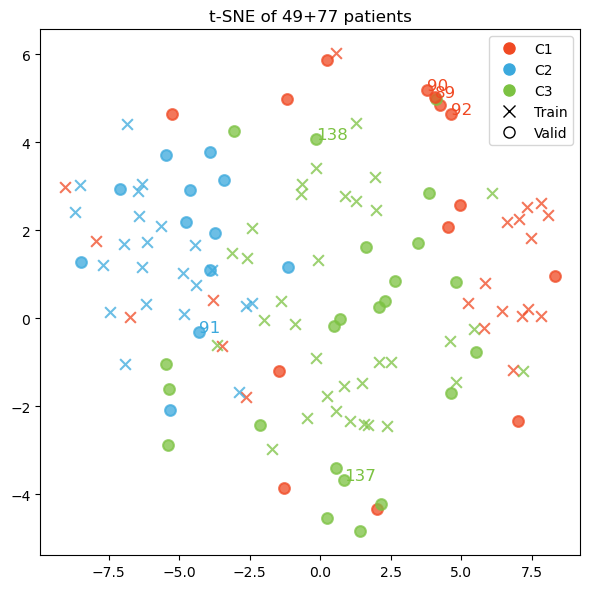

In [89]:
from matplotlib.lines import Line2D

fig, ax = plt.subplots(1, 1, figsize=(6, 6))
lw = 1.5
m_cluster = {"C1": '#F04923', "C2": '#3BA9DD', "C3": '#7CC242', "": "gray"}
m_set = {'Train': 'x', 'Valid': 'o'}
s_size = 60

for _, row in data_pca.iterrows():
    x, y, c, s, o = row[['x', 'y', 'y_true', 'Set', 'label']]
    ax.scatter(
        x, y, s=s_size, marker=m_set[s],
        color=m_cluster[c],
        alpha=0.75, lw=lw  # thin edge for solid dots
    )
    if not pd.isna(o):
        ax.text(x, y, s=o, alpha=1, fontsize=12, color=m_cluster[c])
# --- build legend handles manually ---
cluster_handles = [
    Line2D([0], [0], marker='o', color='none', markerfacecolor=color,
           markeredgecolor=color, markersize=8, label=cluster)
    for cluster, color in m_cluster.items() if cluster != ""
]
set_handles = [
    Line2D([0], [0], marker=marker, color='black', linestyle='None',
           markersize=8, markerfacecolor='none' if set_name == 'Valid' else 'black',
           label=set_name)
    for set_name, marker in m_set.items()
]
ax.legend(handles=cluster_handles + set_handles, loc="best", shadow=False)

ax.set_title("t-SNE of 49+77 patients")
plt.tight_layout()
plt.show()

In [90]:
out = J(OUTPUTROOT,'fig.5C.scatter.tSNE.pdf')
fig.savefig(out, dpi=300, bbox_inches="tight")
print(f"Saving {out}")

write_excel({'fig.5C.data': data_pca}, 'fig.5C.scatter.tSNE', outputdir=OUTPUTROOT)


Saving report_c3/fig.5C.scatter.tSNE.pdf
  append #1 Sheet [fig.5C.data]
writing 1 .xls @ report_c3/fig.5C.scatter.xlsx


## fig 5D

**Use GET_DATA_cmap_drugs.ipynb to generate the washed data**

then plot manually